# Dynamic Longitudinal Maternal Risk Updating

- Builds cumulative prediction windows: **W0, W1, W2, W3, W4**
- Applies **leakage-aware feature selection**
- Performs **preprocessing, cleaning, imputation, encoding, and feature engineering**
- Trains:
  - Logistic Regression
  - Random Forest
  - Extra Trees





In [1]:

%pip install pandas numpy scikit-learn matplotlib jupyter


   ---------------------------------------- 4/4 [isoduration]

Note: you may need to restart the kernel to use updated packages.


In [2]:
"""
Dynamic longitudinal maternal risk updating pipeline.

Implements leakage-aware modeling across cumulative ANC visit windows:
    W0 = baseline only
    W1 = baseline + visit 1
    W2 = baseline + visits 1-2
    W3 = baseline + visits 1-3
    W4 = baseline + visits 1-4

Outputs:
    - CSV summaries of cohort sizes, window feature inventories, model metrics,
      thresholds, predictions, curve points, and feature importance
    - PNG charts for visit coverage, metric trends, ROC/PR/calibration curves,
      confusion matrices, and top feature importances

Designed for the Tanzania maternal health risk stratification dataset.
"""

from __future__ import annotations

import argparse
import json
import math
import os
import re
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.errors import PerformanceWarning
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=PerformanceWarning)

RANDOM_STATE = 42
TARGET_COL = "risk"
ID_COL = "sn"
WINDOWS = ["W0", "W1", "W2", "W3", "W4"]
VISIT_NUMBERS = {"W0": 0, "W1": 1, "W2": 2, "W3": 3, "W4": 4}

COMMON_MISSING_TOKENS = {
    "",
    " ",
    "na",
    "n/a",
    "nan",
    "none",
    "null",
    "nil",
    "not done",
    "notdone",
    "unknown",
    "unk",
    "-",
    "--",
    "---",
    ".",
    "..",
    "...",
    "_",
    "__",
    "___",
}

POSITIVE_TOKENS = {"positive", "p0sitive", "pos", "+ve", "+", "yes", "present", "detected"}
NEGATIVE_TOKENS = {
    "negative",
    "ngative",
    "nergative",
    "negastive",
    "negatve",
    "negarive",
    "megative",
    "nevative",
    "negarivr",
    "-.ve",
    "no",
    "absent",
    "not detected",
}
NORMAL_TOKENS = {"normal", "norma", "norm", "nornal"}
ABNORMAL_TOKENS = {"abnormal", "abnorma", "abnorm", "ab normal"}

OUTCOME_LEAKAGE_EXACT = {
    "mode_of_delivery",
    "live_births",
    "still_births",
    "labour_at_term",
    "post_term",
    "preterm_labour",
    "twins_delivery",
    "number_of_twins",
    "newborn_birth_weight_kg_",
    "newborn_with_weight_4kg_and_above",
    "gender_of_new_born_child",
    "new_born_with_complication",
    "immunization_status",
    "bleeding_during_delivery",
    "bleeding_after_delivery",
    "total_antenatal_visits",
    "other_problems_during_pregnancy",
}

FREE_TEXT_HINTS = (
    "specify",
    "other_",
    "comments",
    "comment",
    "description",
    "indicate_problem",
    "name_of",
)

NUMERIC_NAME_HINTS = (
    "age",
    "week",
    "weeks",
    "days",
    "weight",
    "height",
    "bmi",
    "pressure",
    "pulse",
    "temperature",
    "sugar",
    "haemoglobin",
    "hemoglobin",
    "rate",
    "number",
    "count",
    "contacts",
    "delivery",
    "movement",
    "fundal_height",
    "parity",
    "gravida",
)


@dataclass
class WindowSpec:
    name: str
    baseline_columns: List[str]
    visit_columns: List[str]
    all_feature_columns: List[str]
    cohort_mask: Optional[pd.Series] = None


class MaternalFeatureBuilder(BaseEstimator, TransformerMixin):
    """Train-aware feature cleaning and engineering on pandas DataFrames."""

    def __init__(
        self,
        max_missing_rate: float = 0.98,
        max_cardinality: int = 30,
        verbose: bool = False,
    ) -> None:
        self.max_missing_rate = max_missing_rate
        self.max_cardinality = max_cardinality
        self.verbose = verbose

    def fit(self, X: pd.DataFrame, y: Optional[pd.Series] = None):
        X = X.copy()
        X.columns = [self._sanitize_col(c) for c in X.columns]
        self.original_columns_ = list(X.columns)

        self.bp_cols_ = [c for c in X.columns if "blood_pressure" in c]
        self.date_cols_ = [c for c in X.columns if "date" in c]
        self.id_like_cols_ = [c for c in X.columns if c in {ID_COL} or c.endswith("_id")]

        self.numeric_like_cols_ = []
        self.drop_cols_ = set(self.id_like_cols_)
        self.drop_reasons_: Dict[str, str] = {}

        for col in X.columns:
            if col in self.drop_cols_:
                self.drop_reasons_[col] = "identifier"
                continue

            s = self._normalize_series(X[col])
            missing_rate = s.isna().mean()
            nunique = s.nunique(dropna=True)

            if missing_rate >= self.max_missing_rate:
                self.drop_cols_.add(col)
                self.drop_reasons_[col] = f"missing_rate>={self.max_missing_rate}"
                continue

            if nunique <= 1:
                self.drop_cols_.add(col)
                self.drop_reasons_[col] = "constant_or_single_value"
                continue

            if self._is_explicit_free_text(col):
                self.drop_cols_.add(col)
                self.drop_reasons_[col] = "free_text_by_name"
                continue

            if s.dtype == object:
                numeric_ratio = self._numeric_ratio(s)
                if numeric_ratio >= 0.90 or self._looks_numeric_by_name(col):
                    self.numeric_like_cols_.append(col)
                    continue

                avg_len = s.dropna().astype(str).map(len).mean() if s.dropna().size else 0
                if nunique > self.max_cardinality and avg_len > 8 and col not in self.bp_cols_ and col not in self.date_cols_:
                    self.drop_cols_.add(col)
                    self.drop_reasons_[col] = f"high_cardinality_text>{self.max_cardinality}"

        self.keep_input_cols_ = [c for c in X.columns if c not in self.drop_cols_]
        train_core = self._transform_core(X)
        self.drop_after_transform_ = [c for c in train_core.columns if train_core[c].nunique(dropna=True) <= 1]
        self.final_output_columns_ = [c for c in train_core.columns if c not in self.drop_after_transform_]
        self.output_columns_ = list(self.final_output_columns_)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = self._transform_core(X)
        for col in self.final_output_columns_:
            if col not in X.columns:
                X[col] = np.nan
        X = X[self.final_output_columns_].copy()
        return X

    def _transform_core(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        X.columns = [self._sanitize_col(c) for c in X.columns]
        missing_cols = [c for c in self.keep_input_cols_ if c not in X.columns]
        for c in missing_cols:
            X[c] = np.nan
        X = X[self.keep_input_cols_].copy()

        # Normalize string values first.
        for col in X.columns:
            if X[col].dtype == object:
                X[col] = self._normalize_series(X[col])

        # Convert numeric-like columns.
        for col in self.numeric_like_cols_:
            if col in X.columns and col not in self.bp_cols_ and col not in self.date_cols_:
                X[col] = self._to_numeric(X[col])

        # Expand date columns.
        for col in self.date_cols_:
            if col not in X.columns:
                continue
            dt = pd.to_datetime(X[col], errors="coerce", dayfirst=True)
            X[f"{col}__year"] = dt.dt.year
            X[f"{col}__month"] = dt.dt.month
            X[f"{col}__day"] = dt.dt.day
            X[f"{col}__dayofyear"] = dt.dt.dayofyear
            X.drop(columns=[col], inplace=True)

        # Expand blood pressure columns.
        for col in self.bp_cols_:
            if col not in X.columns:
                continue
            bp = X[col].apply(self._parse_bp)
            X[f"{col}__sys"] = bp.map(lambda v: v[0] if v else np.nan)
            X[f"{col}__dia"] = bp.map(lambda v: v[1] if v else np.nan)
            X[f"{col}__pp"] = X[f"{col}__sys"] - X[f"{col}__dia"]
            X[f"{col}__map"] = (X[f"{col}__sys"] + 2 * X[f"{col}__dia"]) / 3.0
            X[f"{col}__htn_flag"] = ((X[f"{col}__sys"] >= 140) | (X[f"{col}__dia"] >= 90)).astype(float)
            X.drop(columns=[col], inplace=True)

        # Additional clinically meaningful feature engineering.
        X = self._add_bmi_features(X)
        X = self._add_threshold_flags(X)
        X = self._add_visit_observation_counts(X)

        # One last pass: coerce obvious numeric name-hint columns.
        for col in list(X.columns):
            if X[col].dtype == object and self._looks_numeric_by_name(col):
                coerced = self._to_numeric(X[col])
                if coerced.notna().sum() >= max(10, int(0.5 * len(coerced.dropna()))):
                    X[col] = coerced
        return X

    @staticmethod
    def _sanitize_col(col: str) -> str:
        return str(col).strip().lower()

    @staticmethod
    def _normalize_series(s: pd.Series) -> pd.Series:
        s = s.replace({np.nan: np.nan})
        s = s.astype(str).str.strip().str.lower()
        s = s.replace(list(COMMON_MISSING_TOKENS), np.nan)
        s = s.replace("nan", np.nan)
        s = s.replace("nat", np.nan)
        s = s.replace("<na>", np.nan)
        s = s.map(MaternalFeatureBuilder._normalize_token)
        return s

    @staticmethod
    def _normalize_token(val):
        if pd.isna(val):
            return np.nan
        token = str(val).strip().lower()
        if token in COMMON_MISSING_TOKENS:
            return np.nan
        if token in POSITIVE_TOKENS or ("pos" in token and len(token) <= 12):
            return "positive"
        if token in NEGATIVE_TOKENS or ("neg" in token and len(token) <= 15):
            return "negative"
        if token in NORMAL_TOKENS:
            return "normal"
        if token in ABNORMAL_TOKENS:
            return "abnormal"
        if token in {"yes", "y", "true", "done", "given", "present"}:
            return "yes"
        if token in {"no", "n", "false", "not done", "not_given", "absent"}:
            return "no"
        return token

    @staticmethod
    def _to_numeric(s: pd.Series) -> pd.Series:
        return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")

    @staticmethod
    def _numeric_ratio(s: pd.Series) -> float:
        non_null = s.dropna()
        if non_null.empty:
            return 0.0
        coerced = pd.to_numeric(non_null.astype(str).str.replace(",", "", regex=False), errors="coerce")
        return float(coerced.notna().mean())

    @staticmethod
    def _parse_bp(value) -> Optional[Tuple[float, float]]:
        if pd.isna(value):
            return None
        text = str(value).strip().lower()
        match = re.search(r"(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)", text)
        if not match:
            return None
        sys = float(match.group(1))
        dia = float(match.group(2))
        return sys, dia

    @staticmethod
    def _is_explicit_free_text(col: str) -> bool:
        return any(h in col for h in FREE_TEXT_HINTS)

    @staticmethod
    def _looks_numeric_by_name(col: str) -> bool:
        return any(h in col for h in NUMERIC_NAME_HINTS)

    def _add_bmi_features(self, X: pd.DataFrame) -> pd.DataFrame:
        if "height_cm" in X.columns:
            height_m = pd.to_numeric(X["height_cm"], errors="coerce") / 100.0
            if "weight_kg" in X.columns:
                weight = pd.to_numeric(X["weight_kg"], errors="coerce")
                bmi = weight / (height_m ** 2)
                X["bmi_from_height_weight"] = bmi.replace([np.inf, -np.inf], np.nan)
                X["underweight_flag"] = (X["bmi_from_height_weight"] < 18.5).astype(float)
                X["overweight_flag"] = (X["bmi_from_height_weight"] >= 25).astype(float)
            for visit in range(1, 9):
                wcol = f"weight_kg_v{visit}"
                if wcol in X.columns:
                    bmi = pd.to_numeric(X[wcol], errors="coerce") / (height_m ** 2)
                    bmi = bmi.replace([np.inf, -np.inf], np.nan)
                    X[f"bmi_v{visit}"] = bmi
                    X[f"underweight_flag_v{visit}"] = (bmi < 18.5).astype(float)
                    X[f"overweight_flag_v{visit}"] = (bmi >= 25).astype(float)
        return X

    def _add_threshold_flags(self, X: pd.DataFrame) -> pd.DataFrame:
        for col in list(X.columns):
            if X[col].dtype == object:
                continue
            # anaemia flags
            if "hemoglobin_check_result" in col or "haemoglobin_level" in col:
                X[f"{col}__anaemia_flag"] = (pd.to_numeric(X[col], errors="coerce") < 11.0).astype(float)
            if "temperature" in col and "blood_pressure" not in col:
                X[f"{col}__fever_flag"] = (pd.to_numeric(X[col], errors="coerce") >= 37.5).astype(float)
            if "pulse_rate" in col:
                X[f"{col}__tachycardia_flag"] = (pd.to_numeric(X[col], errors="coerce") > 100).astype(float)
            if "blood_sugar_result" in col:
                vals = pd.to_numeric(X[col], errors="coerce")
                X[f"{col}__hyperglycemia_flag"] = (vals >= 7.8).astype(float)
        return X

    def _add_visit_observation_counts(self, X: pd.DataFrame) -> pd.DataFrame:
        visit_counts = {}
        for visit in range(1, 9):
            visit_cols = [c for c in X.columns if re.search(rf"_v{visit}$", c)]
            if visit_cols:
                visit_counts[visit] = X[visit_cols].notna().sum(axis=1)
                X[f"observed_fields_v{visit}"] = visit_counts[visit]
        if visit_counts:
            count_df = pd.DataFrame(visit_counts)
            X["observed_visit_count_total"] = (count_df > 0).sum(axis=1)
        return X


@dataclass
class ModelResult:
    window: str
    model_name: str
    threshold: float
    val_metrics: Dict[str, float]
    test_metrics: Dict[str, float]
    roc_points: pd.DataFrame
    pr_points: pd.DataFrame
    cal_points: pd.DataFrame
    predictions: pd.DataFrame
    feature_importance: pd.DataFrame


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Dynamic longitudinal maternal risk updating pipeline")
    parser.add_argument("--csv_path", type=str, required=True, help="Path to the maternal dataset CSV")
    parser.add_argument("--output_dir", type=str, default="outputs_dynamic_maternal_risk", help="Directory for all outputs")
    parser.add_argument(
        "--models",
        nargs="+",
        default=["logistic", "random_forest", "extra_trees"],
        choices=["logistic", "random_forest", "extra_trees"],
        help="Models to train",
    )
    parser.add_argument(
        "--cohort_mode",
        type=str,
        default="window_specific",
        choices=["window_specific", "anchored_v4"],
        help="window_specific = each window requires data from the current visit; anchored_v4 = same cohort with visit 4 data for all windows",
    )
    parser.add_argument("--train_size", type=float, default=0.70)
    parser.add_argument("--val_size", type=float, default=0.15)
    parser.add_argument("--test_size", type=float, default=0.15)
    parser.add_argument("--min_non_missing_visit_fields", type=int, default=3)
    parser.add_argument("--windows", nargs="+", default=WINDOWS, choices=WINDOWS, help="Prediction windows to run")
    parser.add_argument("--max_missing_rate", type=float, default=0.98)
    parser.add_argument("--max_cardinality", type=int, default=30)
    parser.add_argument("--top_k_features", type=int, default=20)
    parser.add_argument("--no_scale", action="store_true", help="Disable numeric scaling")
    parser.add_argument("--verbose", action="store_true")
    return parser.parse_args()


def ensure_dirs(base_dir: Path) -> Dict[str, Path]:
    subdirs = {
        "base": base_dir,
        "tables": base_dir / "tables",
        "plots": base_dir / "plots",
        "predictions": base_dir / "predictions",
        "feature_importance": base_dir / "feature_importance",
    }
    for p in subdirs.values():
        p.mkdir(parents=True, exist_ok=True)
    return subdirs


def load_dataset(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv(csv_path, low_memory=False)
    df.columns = [str(c).strip().lower() for c in df.columns]
    if TARGET_COL not in df.columns:
        raise ValueError(f"Expected target column '{TARGET_COL}' in the CSV.")
    return df


def clean_target(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip().str.lower()
    df[TARGET_COL] = df[TARGET_COL].replace({"high": 1, "low": 0, "1": 1, "0": 0})
    df = df[df[TARGET_COL].isin([0, 1])].copy()
    df[TARGET_COL] = df[TARGET_COL].astype(int)
    return df


def is_postpartum_col(col: str) -> bool:
    return bool(re.search(r"_v\d.*_p$", col))


def is_visit_col(col: str, visit_no: int) -> bool:
    return bool(re.search(rf"_v{visit_no}$", col)) and not is_postpartum_col(col)


def build_window_specs(df: pd.DataFrame, min_non_missing_visit_fields: int, cohort_mode: str, windows: Sequence[str]) -> Dict[str, WindowSpec]:
    cols = list(df.columns)
    visit_cols = {i: [c for c in cols if is_visit_col(c, i)] for i in range(1, 9)}
    postpartum_cols = [c for c in cols if is_postpartum_col(c)]

    excluded_global = {TARGET_COL}
    excluded_global.update(postpartum_cols)
    excluded_global.update(OUTCOME_LEAKAGE_EXACT)

    baseline_cols = [
        c
        for c in cols
        if c not in excluded_global and not any(is_visit_col(c, i) for i in range(1, 9))
    ]

    window_specs: Dict[str, WindowSpec] = {}
    anchored_mask = None
    if cohort_mode == "anchored_v4":
        v4_cols = visit_cols.get(4, [])
        if v4_cols:
            anchored_mask = (df[v4_cols].notna().sum(axis=1) >= min_non_missing_visit_fields)
        else:
            anchored_mask = pd.Series(True, index=df.index)

    for window in windows:
        visit_no = VISIT_NUMBERS[window]
        cumulative_visit_cols = []
        for i in range(1, visit_no + 1):
            cumulative_visit_cols.extend(visit_cols.get(i, []))

        all_cols = baseline_cols + cumulative_visit_cols

        if window == "W0":
            mask = pd.Series(True, index=df.index)
        elif cohort_mode == "anchored_v4" and anchored_mask is not None:
            mask = anchored_mask.copy()
        else:
            current_visit_cols = visit_cols.get(visit_no, [])
            mask = (df[current_visit_cols].notna().sum(axis=1) >= min_non_missing_visit_fields)

        window_specs[window] = WindowSpec(
            name=window,
            baseline_columns=baseline_cols,
            visit_columns=cumulative_visit_cols,
            all_feature_columns=all_cols,
            cohort_mask=mask,
        )

    return window_specs


def summarize_raw_data(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        rows.append(
            {
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_rate": float(df[col].isna().mean()),
                "n_unique": int(df[col].nunique(dropna=True)),
            }
        )
    return pd.DataFrame(rows).sort_values(["missing_rate", "n_unique"], ascending=[False, False])


def get_models(selected: Sequence[str]) -> Dict[str, BaseEstimator]:
    model_map: Dict[str, BaseEstimator] = {}
    for name in selected:
        if name == "logistic":
            model_map["LogisticRegression"] = LogisticRegression(
                max_iter=4000,
                class_weight="balanced",
                solver="liblinear",
                C=1.0,
                random_state=RANDOM_STATE,
            )
        elif name == "random_forest":
            model_map["RandomForest"] = RandomForestClassifier(
                n_estimators=400,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
        elif name == "extra_trees":
            model_map["ExtraTrees"] = ExtraTreesClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            )
    return model_map


def split_dataframe(
    df_window: pd.DataFrame,
    train_size: float,
    val_size: float,
    test_size: float,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    if not math.isclose(train_size + val_size + test_size, 1.0, abs_tol=1e-6):
        raise ValueError("train_size + val_size + test_size must sum to 1.0")

    train_df, temp_df = train_test_split(
        df_window,
        test_size=(1.0 - train_size),
        stratify=df_window[TARGET_COL],
        random_state=RANDOM_STATE,
    )
    relative_test = test_size / (val_size + test_size)
    val_df, test_df = train_test_split(
        temp_df,
        test_size=relative_test,
        stratify=temp_df[TARGET_COL],
        random_state=RANDOM_STATE,
    )
    return train_df, val_df, test_df


def build_preprocessor(X_train_feat: pd.DataFrame, scale_numeric: bool = True) -> ColumnTransformer:
    numeric_cols = [c for c in X_train_feat.columns if pd.api.types.is_numeric_dtype(X_train_feat[c])]
    categorical_cols = [c for c in X_train_feat.columns if c not in numeric_cols]

    num_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric and numeric_cols:
        num_steps.append(("scaler", StandardScaler(with_mean=False)))
    numeric_pipe = Pipeline(num_steps)

    categorical_pipe = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_cols),
            ("cat", categorical_pipe, categorical_cols),
        ],
        remainder="drop",
        sparse_threshold=0.3,
    )
    return preprocessor


def specificity_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan


def choose_threshold(y_true: np.ndarray, y_prob: np.ndarray) -> float:
    thresholds = np.unique(np.clip(np.round(y_prob, 4), 0, 1))
    if thresholds.size == 0:
        return 0.5
    best_t, best_score = 0.5, -np.inf
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        score = fbeta_score(y_true, y_pred, beta=2, zero_division=0)
        if score > best_score:
            best_score, best_t = score, float(t)
    return best_t


def compute_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> Dict[str, float]:
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "auroc": float(roc_auc_score(y_true, y_prob)),
        "auprc": float(average_precision_score(y_true, y_prob)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "specificity": float(specificity_score(y_true, y_pred)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "f2": float(fbeta_score(y_true, y_pred, beta=2, zero_division=0)),
        "brier": float(brier_score_loss(y_true, y_prob)),
    }


def curve_points(window: str, model_name: str, y_true: np.ndarray, y_prob: np.ndarray) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    fpr, tpr, roc_thr = roc_curve(y_true, y_prob)
    precision, recall, pr_thr = precision_recall_curve(y_true, y_prob)
    frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="quantile")

    roc_df = pd.DataFrame({"window": window, "model": model_name, "fpr": fpr, "tpr": tpr})
    pr_df = pd.DataFrame({"window": window, "model": model_name, "precision": precision, "recall": recall})
    cal_df = pd.DataFrame({"window": window, "model": model_name, "mean_pred": mean_pred, "frac_pos": frac_pos})
    return roc_df, pr_df, cal_df


def extract_feature_importance(model: BaseEstimator, feature_names: Sequence[str], top_k: int) -> pd.DataFrame:
    if hasattr(model, "coef_"):
        importance = np.abs(np.ravel(model.coef_))
    elif hasattr(model, "feature_importances_"):
        importance = np.ravel(model.feature_importances_)
    else:
        return pd.DataFrame(columns=["feature", "importance"])
    feat_df = pd.DataFrame({"feature": feature_names, "importance": importance})
    feat_df = feat_df.sort_values("importance", ascending=False).head(top_k).reset_index(drop=True)
    return feat_df


def get_feature_names(preprocessor: ColumnTransformer) -> List[str]:
    names = list(preprocessor.get_feature_names_out())
    cleaned = [re.sub(r"^(num|cat)__", "", n) for n in names]
    return cleaned


def train_and_evaluate_window(
    df_window: pd.DataFrame,
    window: str,
    models: Dict[str, BaseEstimator],
    args: argparse.Namespace,
) -> Tuple[List[ModelResult], pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    train_df, val_df, test_df = split_dataframe(df_window, args.train_size, args.val_size, args.test_size)

    X_train_raw = train_df.drop(columns=[TARGET_COL])
    X_val_raw = val_df.drop(columns=[TARGET_COL])
    X_test_raw = test_df.drop(columns=[TARGET_COL])
    y_train = train_df[TARGET_COL].to_numpy()
    y_val = val_df[TARGET_COL].to_numpy()
    y_test = test_df[TARGET_COL].to_numpy()

    builder = MaternalFeatureBuilder(
        max_missing_rate=args.max_missing_rate,
        max_cardinality=args.max_cardinality,
        verbose=args.verbose,
    )
    builder.fit(X_train_raw)
    X_train_feat = builder.transform(X_train_raw)
    X_val_feat = builder.transform(X_val_raw)
    X_test_feat = builder.transform(X_test_raw)

    preprocessor = build_preprocessor(X_train_feat, scale_numeric=not args.no_scale)
    preprocessor.fit(X_train_feat)
    X_train = preprocessor.transform(X_train_feat)
    X_val = preprocessor.transform(X_val_feat)
    X_test = preprocessor.transform(X_test_feat)
    feature_names = get_feature_names(preprocessor)

    drop_summary = pd.DataFrame(
        [{"window": window, "column": c, "reason": r} for c, r in builder.drop_reasons_.items()]
    )

    split_summary = pd.DataFrame(
        [
            {
                "window": window,
                "split": split_name,
                "n_rows": len(split_df),
                "positive_rate": split_df[TARGET_COL].mean(),
                "n_raw_features": X_train_raw.shape[1],
                "n_engineered_features_before_encoding": X_train_feat.shape[1],
                "n_encoded_features": X_train.shape[1],
            }
            for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]
        ]
    )

    results: List[ModelResult] = []
    for model_name, model in models.items():
        clf = clone(model)
        clf.fit(X_train, y_train)

        val_prob = clf.predict_proba(X_val)[:, 1]
        threshold = choose_threshold(y_val, val_prob)
        val_metrics = compute_metrics(y_val, val_prob, threshold)

        test_prob = clf.predict_proba(X_test)[:, 1]
        test_metrics = compute_metrics(y_test, test_prob, threshold)
        roc_df, pr_df, cal_df = curve_points(window, model_name, y_test, test_prob)

        y_test_pred = (test_prob >= threshold).astype(int)
        preds_df = pd.DataFrame(
            {
                "window": window,
                "model": model_name,
                "sn": test_df[ID_COL].values if ID_COL in test_df.columns else np.arange(len(test_df)),
                "y_true": y_test,
                "y_prob": test_prob,
                "threshold": threshold,
                "y_pred": y_test_pred,
            }
        )

        feat_imp_df = extract_feature_importance(clf, feature_names, args.top_k_features)
        feat_imp_df.insert(0, "window", window)
        feat_imp_df.insert(1, "model", model_name)

        results.append(
            ModelResult(
                window=window,
                model_name=model_name,
                threshold=threshold,
                val_metrics=val_metrics,
                test_metrics=test_metrics,
                roc_points=roc_df,
                pr_points=pr_df,
                cal_points=cal_df,
                predictions=preds_df,
                feature_importance=feat_imp_df,
            )
        )

    return results, drop_summary, split_summary, pd.DataFrame(
        {
            "window": [window],
            "n_rows": [len(df_window)],
            "positive_rate": [df_window[TARGET_COL].mean()],
            "n_candidate_features": [df_window.drop(columns=[TARGET_COL]).shape[1]],
        }
    )


def save_metrics_and_artifacts(
    all_results: List[ModelResult],
    all_drop_summaries: List[pd.DataFrame],
    all_split_summaries: List[pd.DataFrame],
    all_window_inventories: List[pd.DataFrame],
    dirs: Dict[str, Path],
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    metrics_rows = []
    thresholds_rows = []
    roc_all, pr_all, cal_all = [], [], []
    preds_all, featimp_all = [], []

    for res in all_results:
        metrics_row = {"window": res.window, "model": res.model_name}
        metrics_row.update({f"val_{k}": v for k, v in res.val_metrics.items()})
        metrics_row.update({f"test_{k}": v for k, v in res.test_metrics.items()})
        metrics_rows.append(metrics_row)
        thresholds_rows.append({"window": res.window, "model": res.model_name, "threshold": res.threshold})
        roc_all.append(res.roc_points)
        pr_all.append(res.pr_points)
        cal_all.append(res.cal_points)
        preds_all.append(res.predictions)
        featimp_all.append(res.feature_importance)

    metrics_df = pd.DataFrame(metrics_rows).sort_values(["window", "test_auprc"], ascending=[True, False])
    thresholds_df = pd.DataFrame(thresholds_rows)
    roc_df = pd.concat(roc_all, ignore_index=True) if roc_all else pd.DataFrame()
    pr_df = pd.concat(pr_all, ignore_index=True) if pr_all else pd.DataFrame()
    cal_df = pd.concat(cal_all, ignore_index=True) if cal_all else pd.DataFrame()
    preds_df = pd.concat(preds_all, ignore_index=True) if preds_all else pd.DataFrame()
    featimp_df = pd.concat(featimp_all, ignore_index=True) if featimp_all else pd.DataFrame()
    drop_df = pd.concat(all_drop_summaries, ignore_index=True) if all_drop_summaries else pd.DataFrame()
    split_df = pd.concat(all_split_summaries, ignore_index=True) if all_split_summaries else pd.DataFrame()
    window_df = pd.concat(all_window_inventories, ignore_index=True) if all_window_inventories else pd.DataFrame()

    metrics_df.to_csv(dirs["tables"] / "03_metrics_by_window_model.csv", index=False)
    thresholds_df.to_csv(dirs["tables"] / "04_thresholds.csv", index=False)
    roc_df.to_csv(dirs["tables"] / "05_roc_curve_points.csv", index=False)
    pr_df.to_csv(dirs["tables"] / "06_pr_curve_points.csv", index=False)
    cal_df.to_csv(dirs["tables"] / "07_calibration_curve_points.csv", index=False)
    preds_df.to_csv(dirs["predictions"] / "all_test_predictions.csv", index=False)
    featimp_df.to_csv(dirs["feature_importance"] / "all_top_feature_importances.csv", index=False)
    drop_df.to_csv(dirs["tables"] / "08_dropped_columns_by_window.csv", index=False)
    split_df.to_csv(dirs["tables"] / "09_split_summaries.csv", index=False)
    window_df.to_csv(dirs["tables"] / "02_window_inventory.csv", index=False)

    best_idx = metrics_df.groupby("window")["val_auprc"].idxmax()
    best_df = metrics_df.loc[best_idx].sort_values("window").reset_index(drop=True)
    best_df.to_csv(dirs["tables"] / "10_best_model_per_window.csv", index=False)

    return metrics_df, best_df


def plot_visit_coverage(window_inventory: pd.DataFrame, out_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(window_inventory["window"], window_inventory["n_rows"])
    ax.set_title("Window-wise cohort sizes")
    ax.set_xlabel("Prediction window")
    ax.set_ylabel("Number of records")
    for idx, row in window_inventory.iterrows():
        ax.text(idx, row["n_rows"], f"{int(row['n_rows'])}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    fig.savefig(out_path, dpi=300)
    plt.close(fig)


def plot_metric_trends(best_df: pd.DataFrame, out_path: Path) -> None:
    metrics = ["test_auroc", "test_auprc", "test_recall", "test_specificity", "test_brier"]
    fig, ax = plt.subplots(figsize=(10, 6))
    for metric in metrics:
        ax.plot(best_df["window"], best_df[metric], marker="o", label=metric.replace("test_", ""))
    ax.set_title("Best-model performance trends across windows")
    ax.set_xlabel("Prediction window")
    ax.set_ylabel("Metric value")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(out_path, dpi=300)
    plt.close(fig)


def plot_curve_overlay(curve_df: pd.DataFrame, x_col: str, y_col: str, best_df: pd.DataFrame, title: str, out_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(8, 6))
    best_pairs = set(zip(best_df["window"], best_df["model"]))
    for (window, model), grp in curve_df.groupby(["window", "model"]):
        if (window, model) not in best_pairs:
            continue
        ax.plot(grp[x_col], grp[y_col], label=f"{window}-{model}")
    if x_col == "mean_pred" and y_col == "frac_pos":
        ax.plot([0, 1], [0, 1], linestyle="--")
        ax.set_xlabel("Mean predicted probability")
        ax.set_ylabel("Fraction positive")
    elif x_col == "fpr":
        ax.plot([0, 1], [0, 1], linestyle="--")
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
    else:
        ax.set_xlabel(x_col.replace("_", " ").title())
        ax.set_ylabel(y_col.replace("_", " ").title())
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(out_path, dpi=300)
    plt.close(fig)


def plot_confusion_matrices(preds_path: Path, best_df: pd.DataFrame, out_dir: Path) -> None:
    preds = pd.read_csv(preds_path)
    out_dir.mkdir(parents=True, exist_ok=True)
    for _, row in best_df.iterrows():
        subset = preds[(preds["window"] == row["window"]) & (preds["model"] == row["model"])]
        if subset.empty:
            continue
        cm = confusion_matrix(subset["y_true"], subset["y_pred"], labels=[0, 1])
        fig, ax = plt.subplots(figsize=(4.5, 4.0))
        im = ax.imshow(cm)
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Pred Low", "Pred High"])
        ax.set_yticklabels(["True Low", "True High"])
        ax.set_title(f"Confusion matrix: {row['window']} - {row['model']}")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        plt.tight_layout()
        fig.savefig(out_dir / f"confusion_{row['window']}_{row['model']}.png", dpi=300)
        plt.close(fig)


def plot_top_features(featimp_path: Path, best_df: pd.DataFrame, out_dir: Path) -> None:
    featimp = pd.read_csv(featimp_path)
    out_dir.mkdir(parents=True, exist_ok=True)
    for _, row in best_df.iterrows():
        subset = featimp[(featimp["window"] == row["window"]) & (featimp["model"] == row["model"])]
        if subset.empty:
            continue
        subset = subset.sort_values("importance", ascending=True)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.barh(subset["feature"], subset["importance"])
        ax.set_title(f"Top features: {row['window']} - {row['model']}")
        ax.set_xlabel("Importance")
        plt.tight_layout()
        fig.savefig(out_dir / f"top_features_{row['window']}_{row['model']}.png", dpi=300)
        plt.close(fig)


def main() -> None:
    args = parse_args()
    out_base = Path(args.output_dir)
    dirs = ensure_dirs(out_base)

    config_path = dirs["base"] / "run_config.json"
    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(vars(args), f, indent=2)

    df = load_dataset(args.csv_path)
    df = clean_target(df)
    df.head(500).to_csv(dirs["tables"] / "00_cleaned_input_snapshot_head.csv", index=False)
    raw_summary = summarize_raw_data(df)
    raw_summary.to_csv(dirs["tables"] / "01_raw_data_profile.csv", index=False)

    window_specs = build_window_specs(df, args.min_non_missing_visit_fields, args.cohort_mode, args.windows)
    models = get_models(args.models)

    all_results: List[ModelResult] = []
    all_drop_summaries: List[pd.DataFrame] = []
    all_split_summaries: List[pd.DataFrame] = []
    all_window_inventories: List[pd.DataFrame] = []

    for window in args.windows:
        spec = window_specs[window]
        mask = spec.cohort_mask if spec.cohort_mask is not None else pd.Series(True, index=df.index)
        df_window = df.loc[mask, [ID_COL] + spec.all_feature_columns + [TARGET_COL]].copy() if ID_COL in df.columns else df.loc[mask, spec.all_feature_columns + [TARGET_COL]].copy()

        # Drop duplicate columns if ID_COL already in baseline columns.
        df_window = df_window.loc[:, ~df_window.columns.duplicated()].copy()

        window_results, drop_summary, split_summary, window_inventory = train_and_evaluate_window(df_window, window, models, args)
        all_results.extend(window_results)
        all_drop_summaries.append(drop_summary)
        all_split_summaries.append(split_summary)
        window_inventory.insert(1, "n_baseline_columns", len(spec.baseline_columns))
        window_inventory.insert(2, "n_visit_columns", len(spec.visit_columns))
        window_inventory.insert(3, "n_all_feature_columns", len(spec.all_feature_columns))
        all_window_inventories.append(window_inventory)

        if args.verbose:
            print(f"Completed {window} on {len(df_window)} rows with {len(models)} models")

    metrics_df, best_df = save_metrics_and_artifacts(
        all_results,
        all_drop_summaries,
        all_split_summaries,
        all_window_inventories,
        dirs,
    )

    window_inventory = pd.concat(all_window_inventories, ignore_index=True)
    plot_visit_coverage(window_inventory, dirs["plots"] / "01_window_cohort_sizes.png")
    plot_metric_trends(best_df, dirs["plots"] / "02_metric_trends_best_models.png")

    roc_df = pd.read_csv(dirs["tables"] / "05_roc_curve_points.csv")
    pr_df = pd.read_csv(dirs["tables"] / "06_pr_curve_points.csv")
    cal_df = pd.read_csv(dirs["tables"] / "07_calibration_curve_points.csv")

    plot_curve_overlay(roc_df, "fpr", "tpr", best_df, "ROC curves for best models", dirs["plots"] / "03_roc_best_models.png")
    plot_curve_overlay(pr_df, "recall", "precision", best_df, "Precision-recall curves for best models", dirs["plots"] / "04_pr_best_models.png")
    plot_curve_overlay(cal_df, "mean_pred", "frac_pos", best_df, "Calibration curves for best models", dirs["plots"] / "05_calibration_best_models.png")
    plot_confusion_matrices(dirs["predictions"] / "all_test_predictions.csv", best_df, dirs["plots"] / "confusion_matrices")
    plot_top_features(dirs["feature_importance"] / "all_top_feature_importances.csv", best_df, dirs["plots"] / "top_features")

    summary = {
        "n_rows": int(len(df)),
        "n_columns": int(df.shape[1]),
        "class_distribution": df[TARGET_COL].value_counts().to_dict(),
        "windows": args.windows,
        "best_models": best_df[["window", "model", "test_auroc", "test_auprc", "test_recall", "test_brier"]].to_dict(orient="records"),
    }
    with open(dirs["base"] / "run_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    print("\nPipeline completed successfully.")
    print(f"Outputs saved to: {dirs['base'].resolve()}")





from types import SimpleNamespace
from IPython.display import display, Image, Markdown

def run_pipeline_notebook(
    csv_path="maternal_dataset_csv.csv",
    output_dir="maternal_dynamic_results",
    models=("logistic", "random_forest", "extra_trees"),
    cohort_mode="window_specific",
    train_size=0.70,
    val_size=0.15,
    test_size=0.15,
    min_non_missing_visit_fields=3,
    windows=("W0", "W1", "W2", "W3", "W4"),
    max_missing_rate=0.98,
    max_cardinality=30,
    top_k_features=20,
    no_scale=False,
    verbose=True,
):
    args = SimpleNamespace(
        csv_path=str(csv_path),
        output_dir=str(output_dir),
        models=list(models),
        cohort_mode=cohort_mode,
        train_size=float(train_size),
        val_size=float(val_size),
        test_size=float(test_size),
        min_non_missing_visit_fields=int(min_non_missing_visit_fields),
        windows=list(windows),
        max_missing_rate=float(max_missing_rate),
        max_cardinality=int(max_cardinality),
        top_k_features=int(top_k_features),
        no_scale=bool(no_scale),
        verbose=bool(verbose),
    )

    out_base = Path(args.output_dir)
    dirs = ensure_dirs(out_base)

    config_path = dirs["base"] / "run_config.json"
    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(vars(args), f, indent=2)

    df = load_dataset(args.csv_path)
    df = clean_target(df)
    df.head(500).to_csv(dirs["tables"] / "00_cleaned_input_snapshot_head.csv", index=False)
    raw_summary = summarize_raw_data(df)
    raw_summary.to_csv(dirs["tables"] / "01_raw_data_profile.csv", index=False)

    window_specs = build_window_specs(df, args.min_non_missing_visit_fields, args.cohort_mode, args.windows)
    models_dict = get_models(args.models)

    all_results = []
    all_drop_summaries = []
    all_split_summaries = []
    all_window_inventories = []

    for window in args.windows:
        spec = window_specs[window]
        mask = spec.cohort_mask if spec.cohort_mask is not None else pd.Series(True, index=df.index)
        if ID_COL in df.columns:
            cols = [ID_COL] + spec.all_feature_columns + [TARGET_COL]
        else:
            cols = spec.all_feature_columns + [TARGET_COL]
        df_window = df.loc[mask, cols].copy()
        df_window = df_window.loc[:, ~df_window.columns.duplicated()].copy()

        window_results, drop_summary, split_summary, window_inventory = train_and_evaluate_window(
            df_window, window, models_dict, args
        )
        all_results.extend(window_results)
        all_drop_summaries.append(drop_summary)
        all_split_summaries.append(split_summary)
        window_inventory.insert(1, "n_baseline_columns", len(spec.baseline_columns))
        window_inventory.insert(2, "n_visit_columns", len(spec.visit_columns))
        window_inventory.insert(3, "n_all_feature_columns", len(spec.all_feature_columns))
        all_window_inventories.append(window_inventory)

        if args.verbose:
            print(f"Completed {window} on {len(df_window)} rows with {len(models_dict)} models")

    metrics_df, best_df = save_metrics_and_artifacts(
        all_results,
        all_drop_summaries,
        all_split_summaries,
        all_window_inventories,
        dirs,
    )

    window_inventory = pd.concat(all_window_inventories, ignore_index=True)
    plot_visit_coverage(window_inventory, dirs["plots"] / "01_window_cohort_sizes.png")
    plot_metric_trends(best_df, dirs["plots"] / "02_metric_trends_best_models.png")

    roc_df = pd.read_csv(dirs["tables"] / "05_roc_curve_points.csv")
    pr_df = pd.read_csv(dirs["tables"] / "06_pr_curve_points.csv")
    cal_df = pd.read_csv(dirs["tables"] / "07_calibration_curve_points.csv")

    plot_curve_overlay(roc_df, "fpr", "tpr", best_df, "ROC curves for best models", dirs["plots"] / "03_roc_best_models.png")
    plot_curve_overlay(pr_df, "recall", "precision", best_df, "Precision-recall curves for best models", dirs["plots"] / "04_pr_best_models.png")
    plot_curve_overlay(cal_df, "mean_pred", "frac_pos", best_df, "Calibration curves for best models", dirs["plots"] / "05_calibration_best_models.png")
    plot_confusion_matrices(dirs["predictions"] / "all_test_predictions.csv", best_df, dirs["plots"] / "confusion_matrices")
    plot_top_features(dirs["feature_importance"] / "all_top_feature_importances.csv", best_df, dirs["plots"] / "top_features")

    summary = {
        "n_rows": int(len(df)),
        "n_columns": int(df.shape[1]),
        "class_distribution": df[TARGET_COL].value_counts().to_dict(),
        "windows": args.windows,
        "best_models": best_df[["window", "model", "test_auroc", "test_auprc", "test_recall", "test_brier"]].to_dict(orient="records"),
    }
    with open(dirs["base"] / "run_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    print("\nPipeline completed successfully.")
    print(f"Outputs saved to: {dirs['base'].resolve()}")
    return dirs, metrics_df, best_df, summary


def show_run_outputs(output_dir):
    output_dir = Path(output_dir)
    tables_dir = output_dir / "tables"
    plots_dir = output_dir / "plots"

    display(Markdown("### Best model per window"))
    best = pd.read_csv(tables_dir / "10_best_model_per_window.csv")
    display(best)

    display(Markdown("### Metrics by window and model"))
    metrics = pd.read_csv(tables_dir / "03_metrics_by_window_model.csv")
    display(metrics)

    for img_name in [
        "01_window_cohort_sizes.png",
        "02_metric_trends_best_models.png",
        "03_roc_best_models.png",
        "04_pr_best_models.png",
        "05_calibration_best_models.png",
    ]:
        img_path = plots_dir / img_name
        if img_path.exists():
            display(Markdown(f"### {img_name}"))
            display(Image(filename=str(img_path)))


## Configure paths and experiment settings

- Set `csv_path` to your dataset file
- Set `output_dir` to where you want all CSVs and figures to be saved
- You can start with all windows and all models, or run only a quick subset first


In [4]:
csv_path = "C:/Users/saiprasad.potharaju/Documents/Maternal_risk/maternal_dataset_csv.csv"   # change this to your local dataset path
output_dir = "maternal_dynamic_results"

models = ("logistic", "random_forest", "extra_trees")
windows = ("W0", "W1", "W2", "W3", "W4")

# For a quick test, use:
# models = ("logistic",)
# windows = ("W0", "W1")

cohort_mode = "window_specific"   # or "anchored_v4"
train_size = 0.70
val_size = 0.15
test_size = 0.15
min_non_missing_visit_fields = 3
max_missing_rate = 0.98
max_cardinality = 30
top_k_features = 20
no_scale = False
verbose = True

## Run the full pipeline

In [5]:
dirs, metrics_df, best_df, summary = run_pipeline_notebook(
    csv_path=csv_path,
    output_dir=output_dir,
    models=models,
    cohort_mode=cohort_mode,
    train_size=train_size,
    val_size=val_size,
    test_size=test_size,
    min_non_missing_visit_fields=min_non_missing_visit_fields,
    windows=windows,
    max_missing_rate=max_missing_rate,
    max_cardinality=max_cardinality,
    top_k_features=top_k_features,
    no_scale=no_scale,
    verbose=verbose,
)

summary

Completed W0 on 8817 rows with 3 models
Completed W1 on 8817 rows with 3 models
Completed W2 on 6934 rows with 3 models
Completed W3 on 5157 rows with 3 models
Completed W4 on 3021 rows with 3 models

Pipeline completed successfully.
Outputs saved to: C:\Users\saiprasad.potharaju\Documents\Maternal_risk\maternal_dynamic_results


{'n_rows': 8817,
 'n_columns': 683,
 'class_distribution': {1: 5510, 0: 3307},
 'windows': ['W0', 'W1', 'W2', 'W3', 'W4'],
 'best_models': [{'window': 'W0',
   'model': 'ExtraTrees',
   'test_auroc': 0.6354609548699145,
   'test_auprc': 0.7742663682314006,
   'test_recall': 0.9987908101571947,
   'test_brier': 0.22221081486752023},
  {'window': 'W1',
   'model': 'RandomForest',
   'test_auroc': 0.9679174630416977,
   'test_auprc': 0.9854116565473434,
   'test_recall': 0.9588875453446191,
   'test_brier': 0.07733853482000863},
  {'window': 'W2',
   'model': 'RandomForest',
   'test_auroc': 0.9681171021340753,
   'test_auprc': 0.9832450968087993,
   'test_recall': 0.9654631083202512,
   'test_brier': 0.09358908887720778},
  {'window': 'W3',
   'model': 'RandomForest',
   'test_auroc': 0.9390719142114863,
   'test_auprc': 0.9673812382014928,
   'test_recall': 0.9410480349344978,
   'test_brier': 0.11178769095270304},
  {'window': 'W4',
   'model': 'RandomForest',
   'test_auroc': 0.931283

## Preview key result tables and figures

### Best model per window

,window,model,val_auroc,val_auprc,val_accuracy,val_balanced_accuracy,val_precision,val_recall,val_specificity,val_f1,...,test_auroc,test_auprc,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_specificity,test_f1,test_f2,test_brier
0,W0,ExtraTrees,0.628596,0.773121,0.625094,0.500000,0.625094,1.000000,0.000000,0.769302,...,0.635461,0.774266,0.634165,0.512500,0.631016,0.998791,0.026210,0.773408,0.894520,0.222211
1,W1,RandomForest,0.963758,0.982799,0.856387,0.822186,0.835616,0.958888,0.685484,0.893018,...,0.967917,0.985412,0.856387,0.822186,0.835616,0.958888,0.685484,0.893018,0.931407,0.077339
2,W2,RandomForest,0.958272,0.979070,0.849038,0.817517,0.824324,0.957614,0.677419,0.885984,...,0.968117,0.983245,0.853026,0.820603,0.824397,0.965463,0.675743,0.889371,0.933515,0.093589
3,W3,RandomForest,0.939369,0.965591,0.816537,0.786600,0.785199,0.949782,0.623418,0.859684,...,0.939072,0.967381,0.790698,0.756916,0.761484,0.941048,0.572785,0.841797,0.898666,0.111788
4,W4,RandomForest,0.938021,0.960944,0.825607,0.819331,0.779720,0.933054,0.705607,0.849524,...,0.931283,0.957780,0.808370,0.803513,0.775362,0.895397,0.711628,0.831068,0.868506,0.125289


### Metrics by window and model

,window,model,val_auroc,val_auprc,val_accuracy,val_balanced_accuracy,val_precision,val_recall,val_specificity,val_f1,...,test_auroc,test_auprc,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_specificity,test_f1,test_f2,test_brier
0,W0,RandomForest,0.623901,0.768106,0.625850,0.501008,0.625567,1.000000,0.002016,0.769660,...,0.655101,0.784919,0.633409,0.513106,0.631336,0.993954,0.032258,0.772194,0.891540,0.214851
1,W0,ExtraTrees,0.628596,0.773121,0.625094,0.500000,0.625094,1.000000,0.000000,0.769302,...,0.635461,0.774266,0.634165,0.512500,0.631016,0.998791,0.026210,0.773408,0.894520,0.222211
2,W0,LogisticRegression,0.587305,0.734739,0.625094,0.500000,0.625094,1.000000,0.000000,0.769302,...,0.627782,0.767590,0.624339,0.499395,0.624811,0.998791,0.000000,0.768730,0.892009,0.233195
3,W1,RandomForest,0.963758,0.982799,0.856387,0.822186,0.835616,0.958888,0.685484,0.893018,...,0.967917,0.985412,0.856387,0.822186,0.835616,0.958888,0.685484,0.893018,0.931407,0.077339
4,W1,LogisticRegression,0.854553,0.919652,0.772487,0.708677,0.746255,0.963724,0.453629,0.841161,...,0.953341,0.974926,0.630385,0.507056,0.628419,1.000000,0.014113,0.771815,0.894247,0.084872
5,W1,ExtraTrees,0.890522,0.940612,0.727135,0.646982,0.705467,0.967352,0.326613,0.815910,...,0.904723,0.948469,0.717309,0.631053,0.695090,0.975816,0.286290,0.811871,0.902887,0.127525
6,W2,RandomForest,0.958272,0.979070,0.849038,0.817517,0.824324,0.957614,0.677419,0.885984,...,0.968117,0.983245,0.853026,0.820603,0.824397,0.965463,0.675743,0.889371,0.933515,0.093589
7,W2,LogisticRegression,0.845959,0.909291,0.747115,0.682813,0.717442,0.968603,0.397022,0.824315,...,0.939020,0.965911,0.613833,0.502475,0.613090,1.000000,0.004950,0.760143,0.887929,0.097914
8,W2,ExtraTrees,0.888879,0.936145,0.708654,0.630450,0.683114,0.978022,0.282878,0.804390,...,0.887946,0.936072,0.722382,0.648664,0.693764,0.978022,0.319307,0.811726,0.903947,0.138042
9,W3,RandomForest,0.939369,0.965591,0.816537,0.786600,0.785199,0.949782,0.623418,0.859684,...,0.939072,0.967381,0.790698,0.756916,0.761484,0.941048,0.572785,0.841797,0.898666,0.111788


### 01_window_cohort_sizes.png

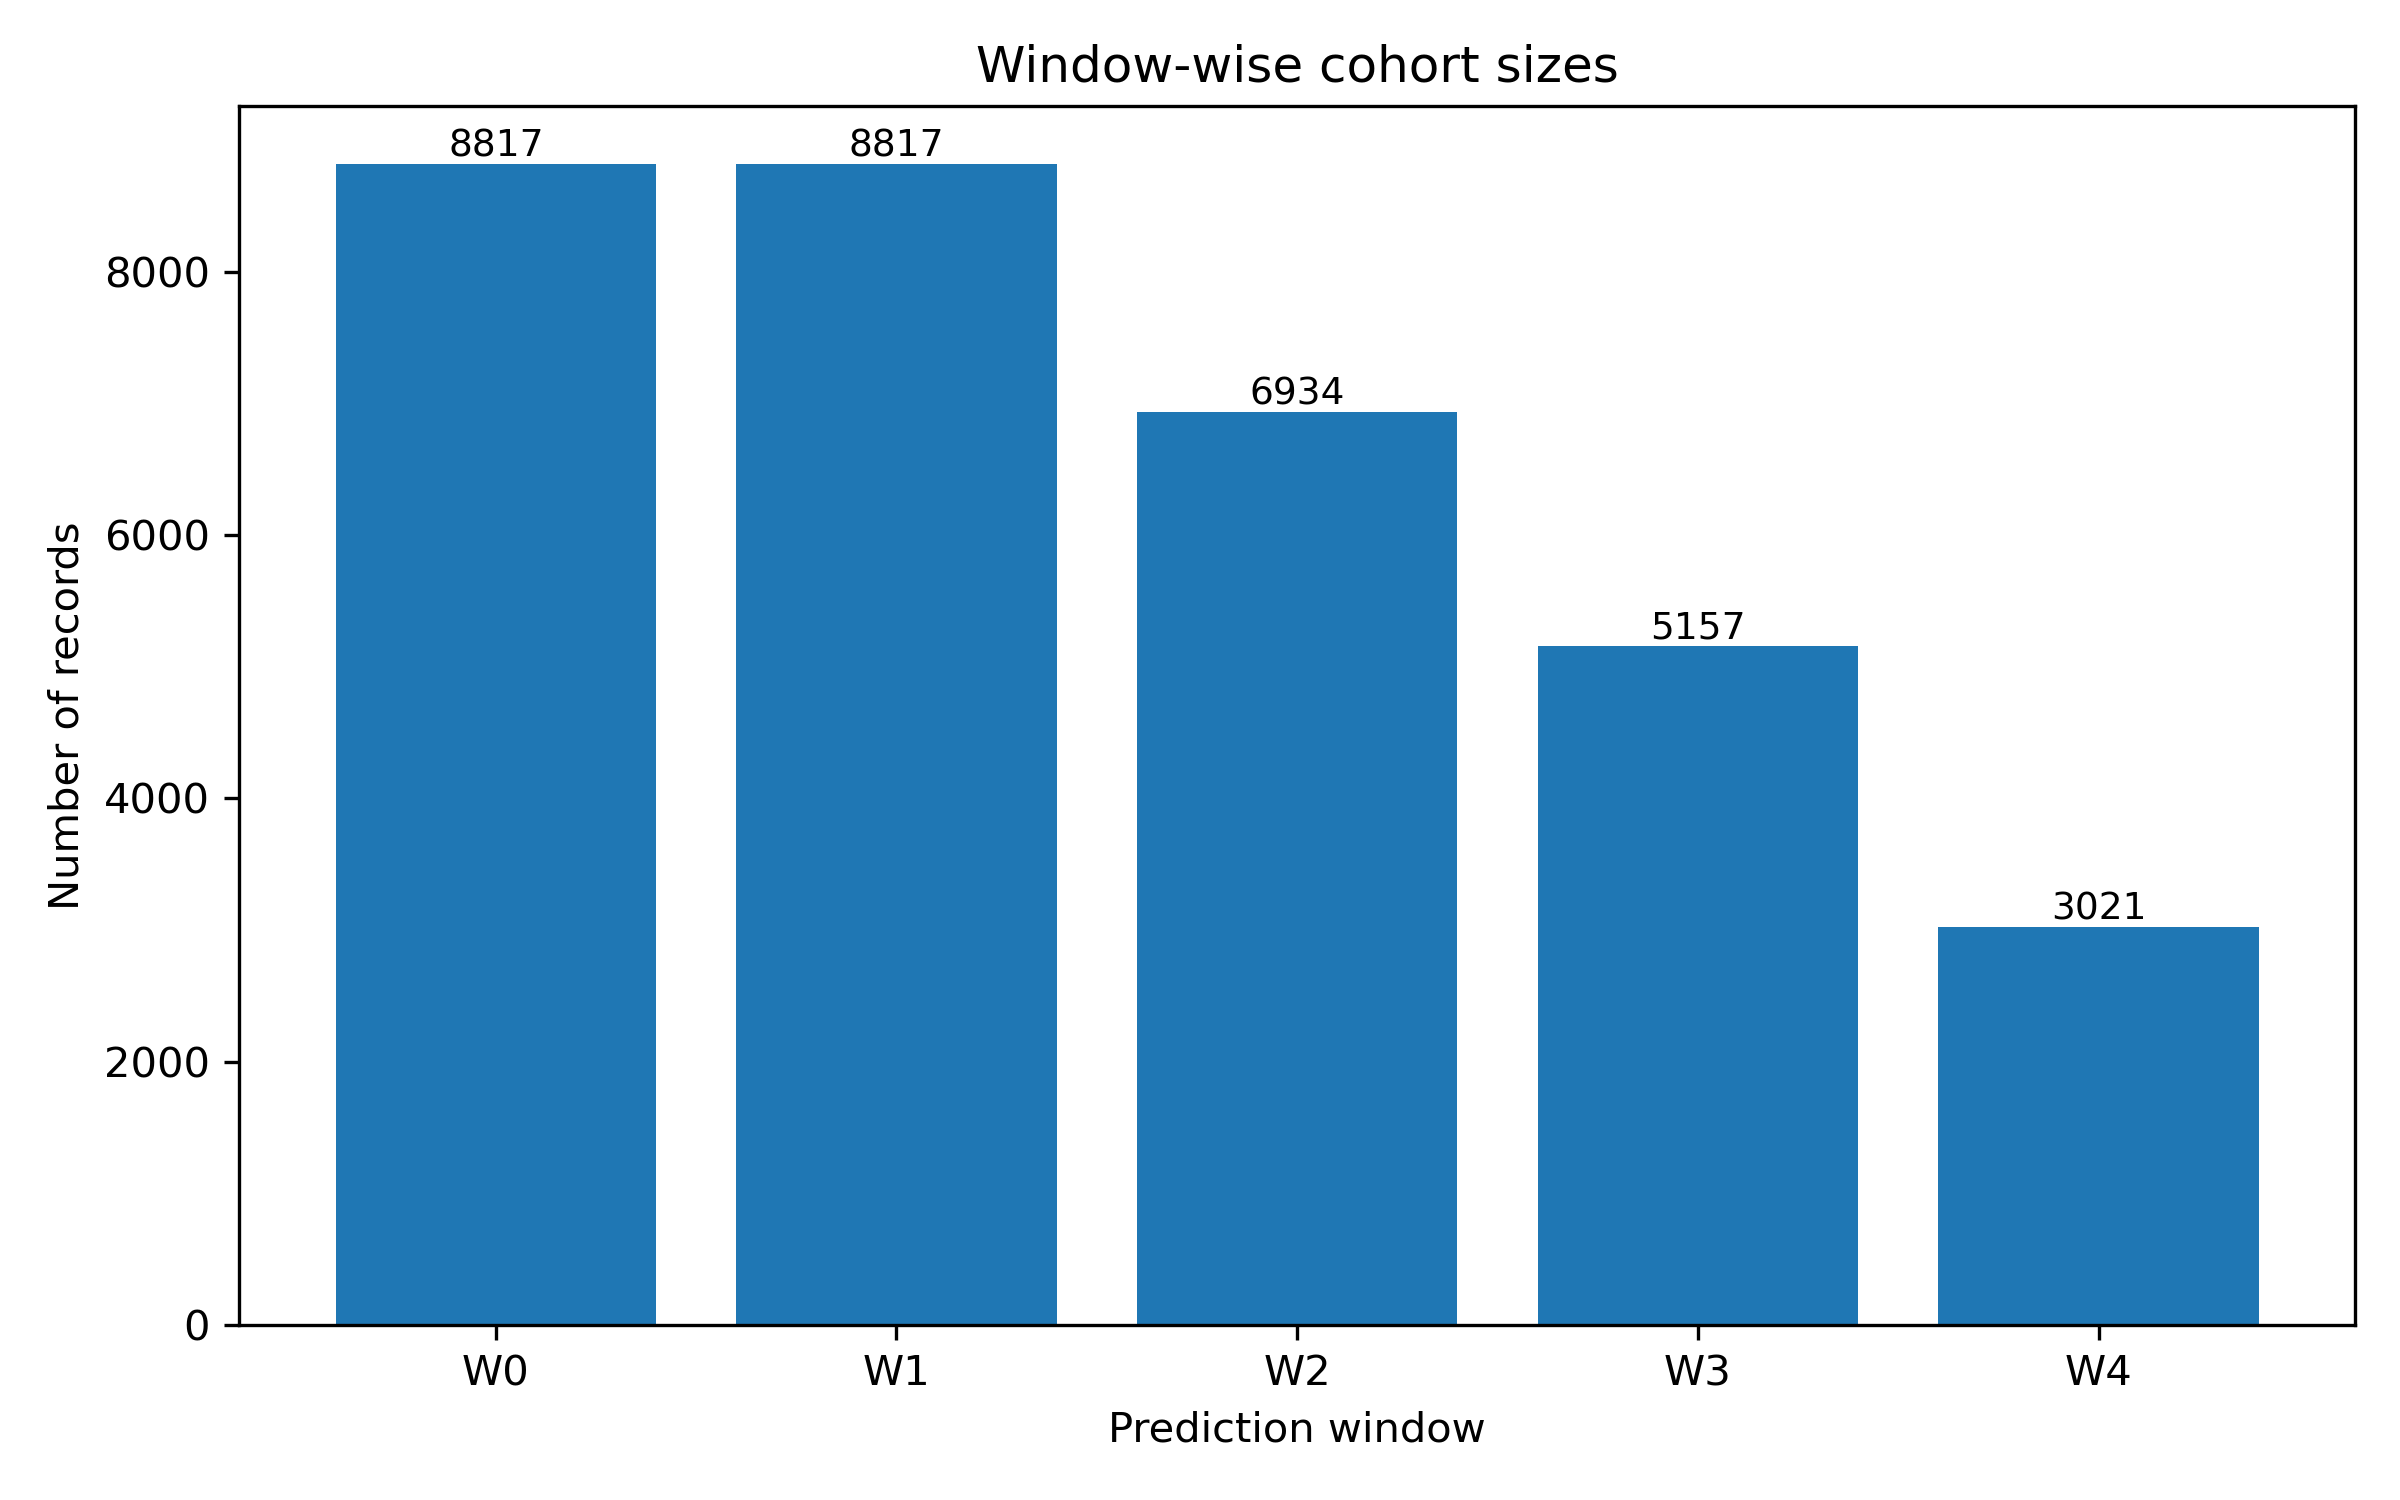

### 02_metric_trends_best_models.png

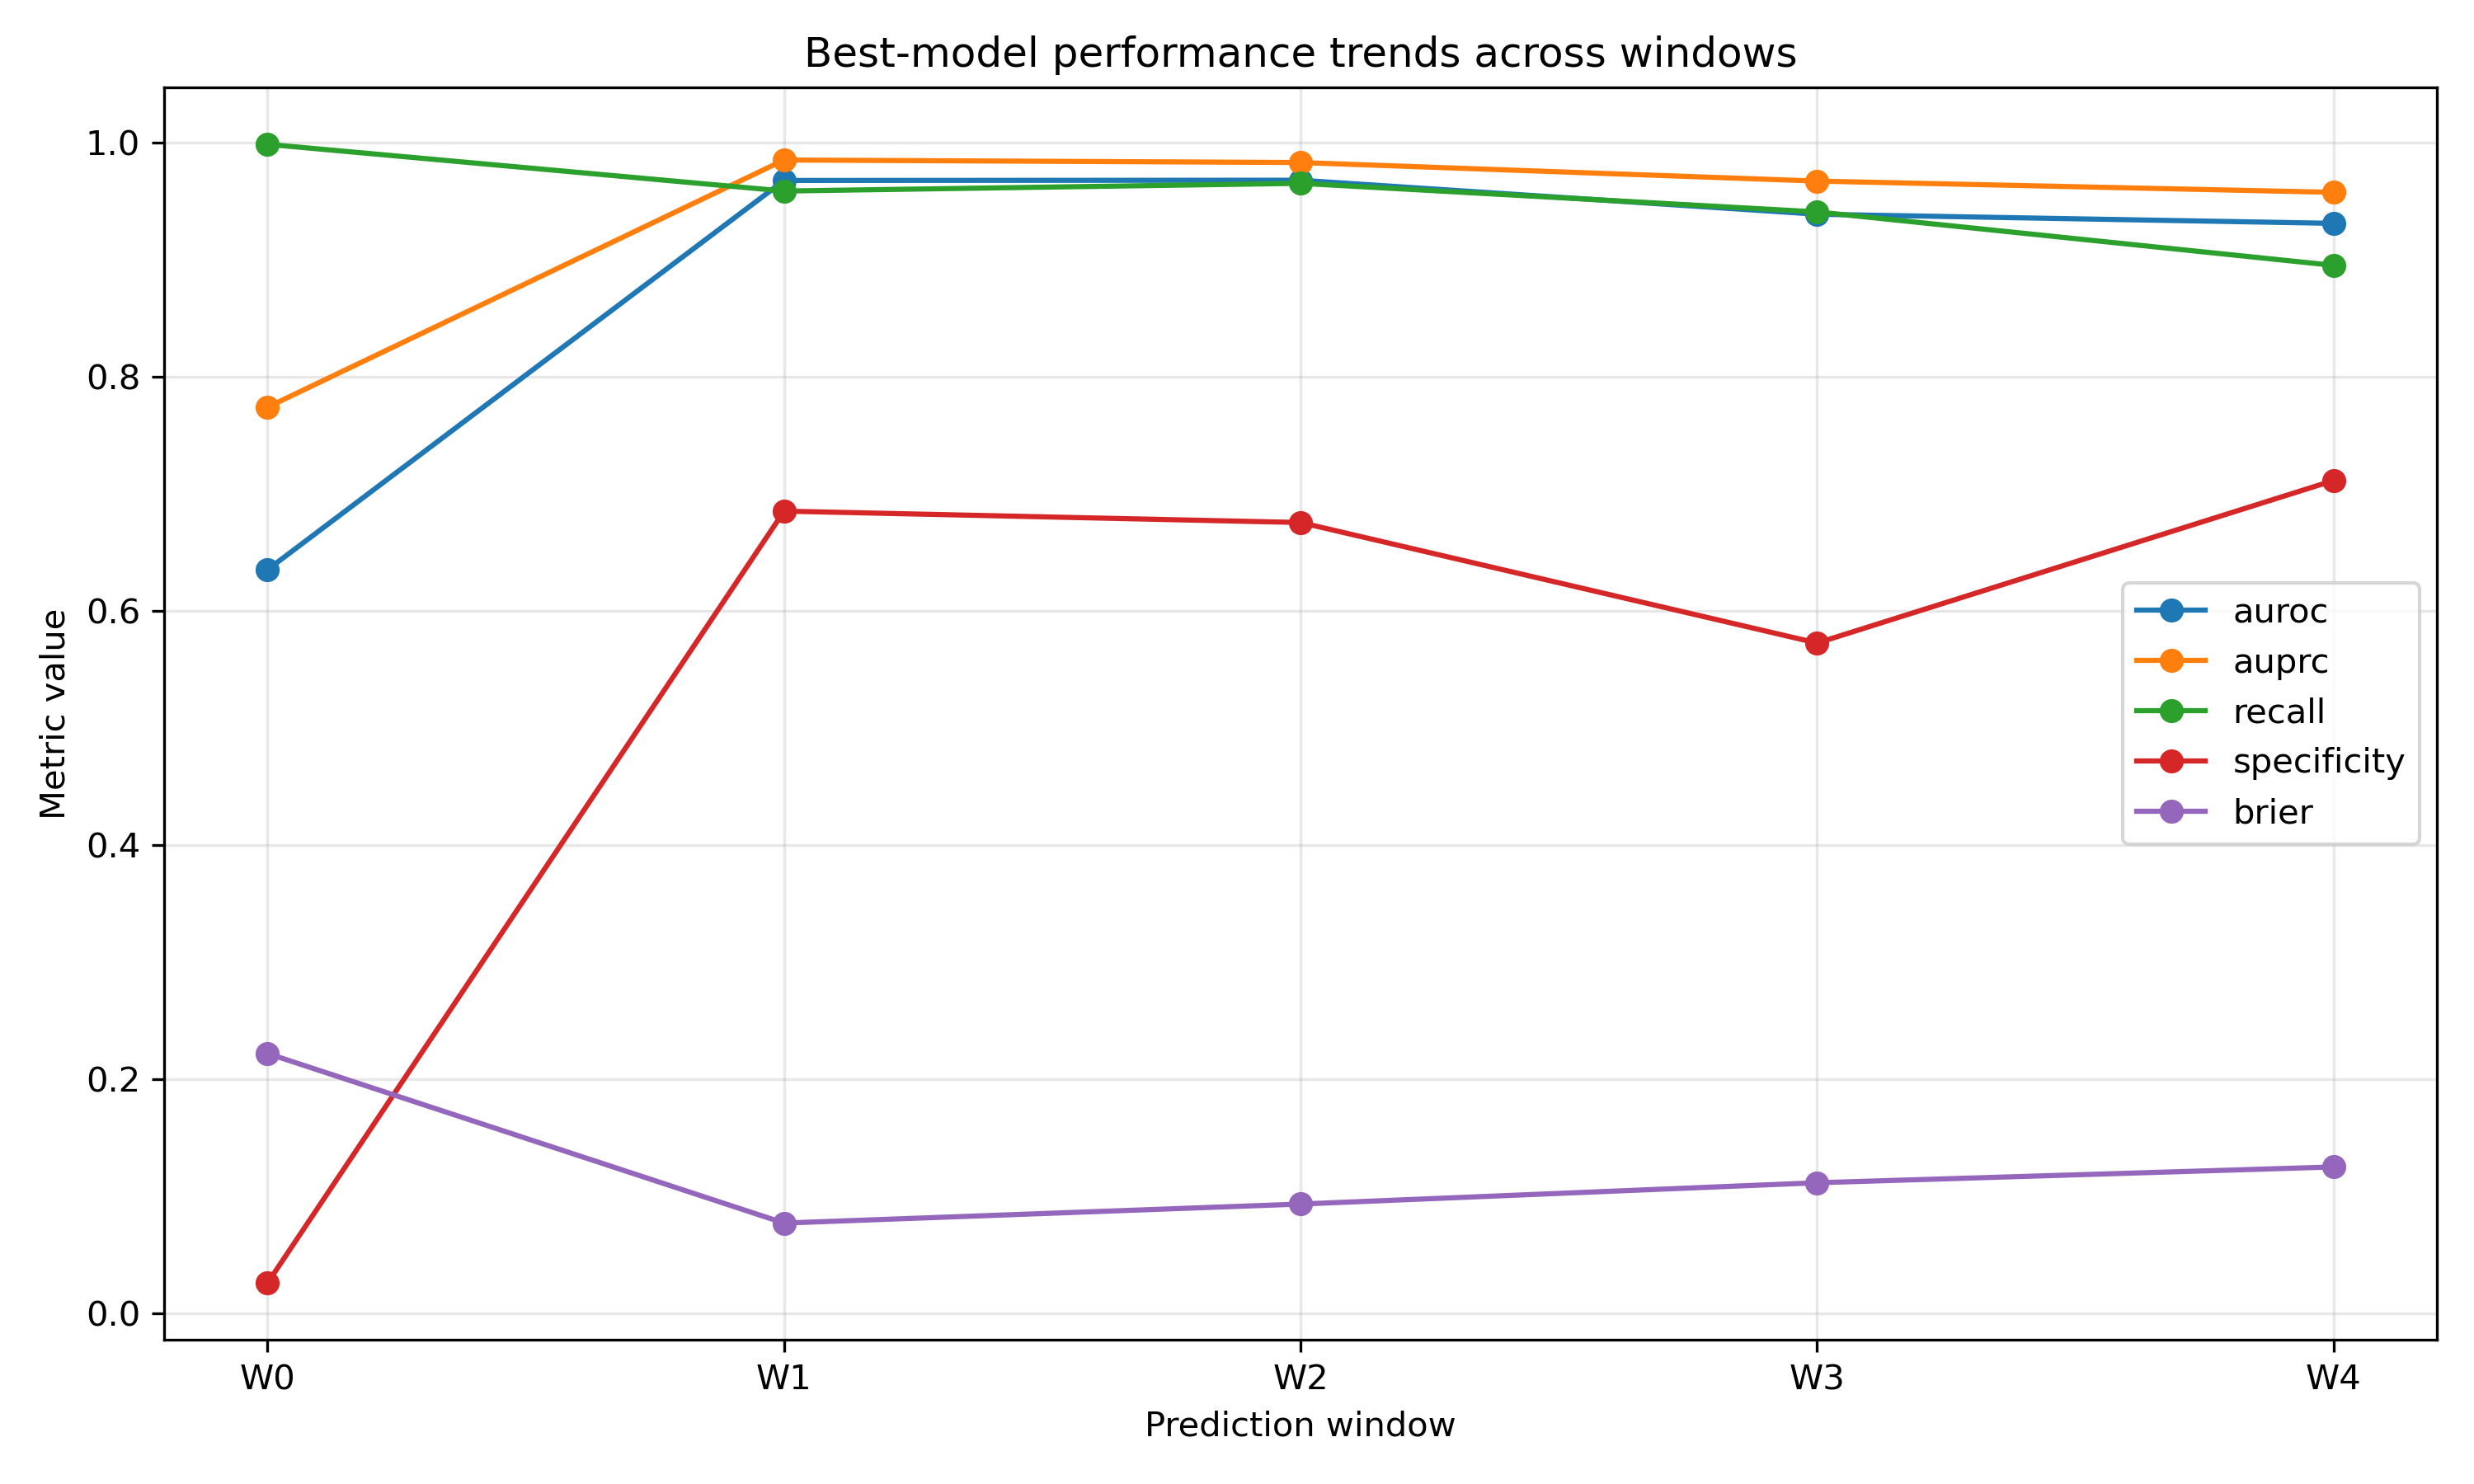

### 03_roc_best_models.png

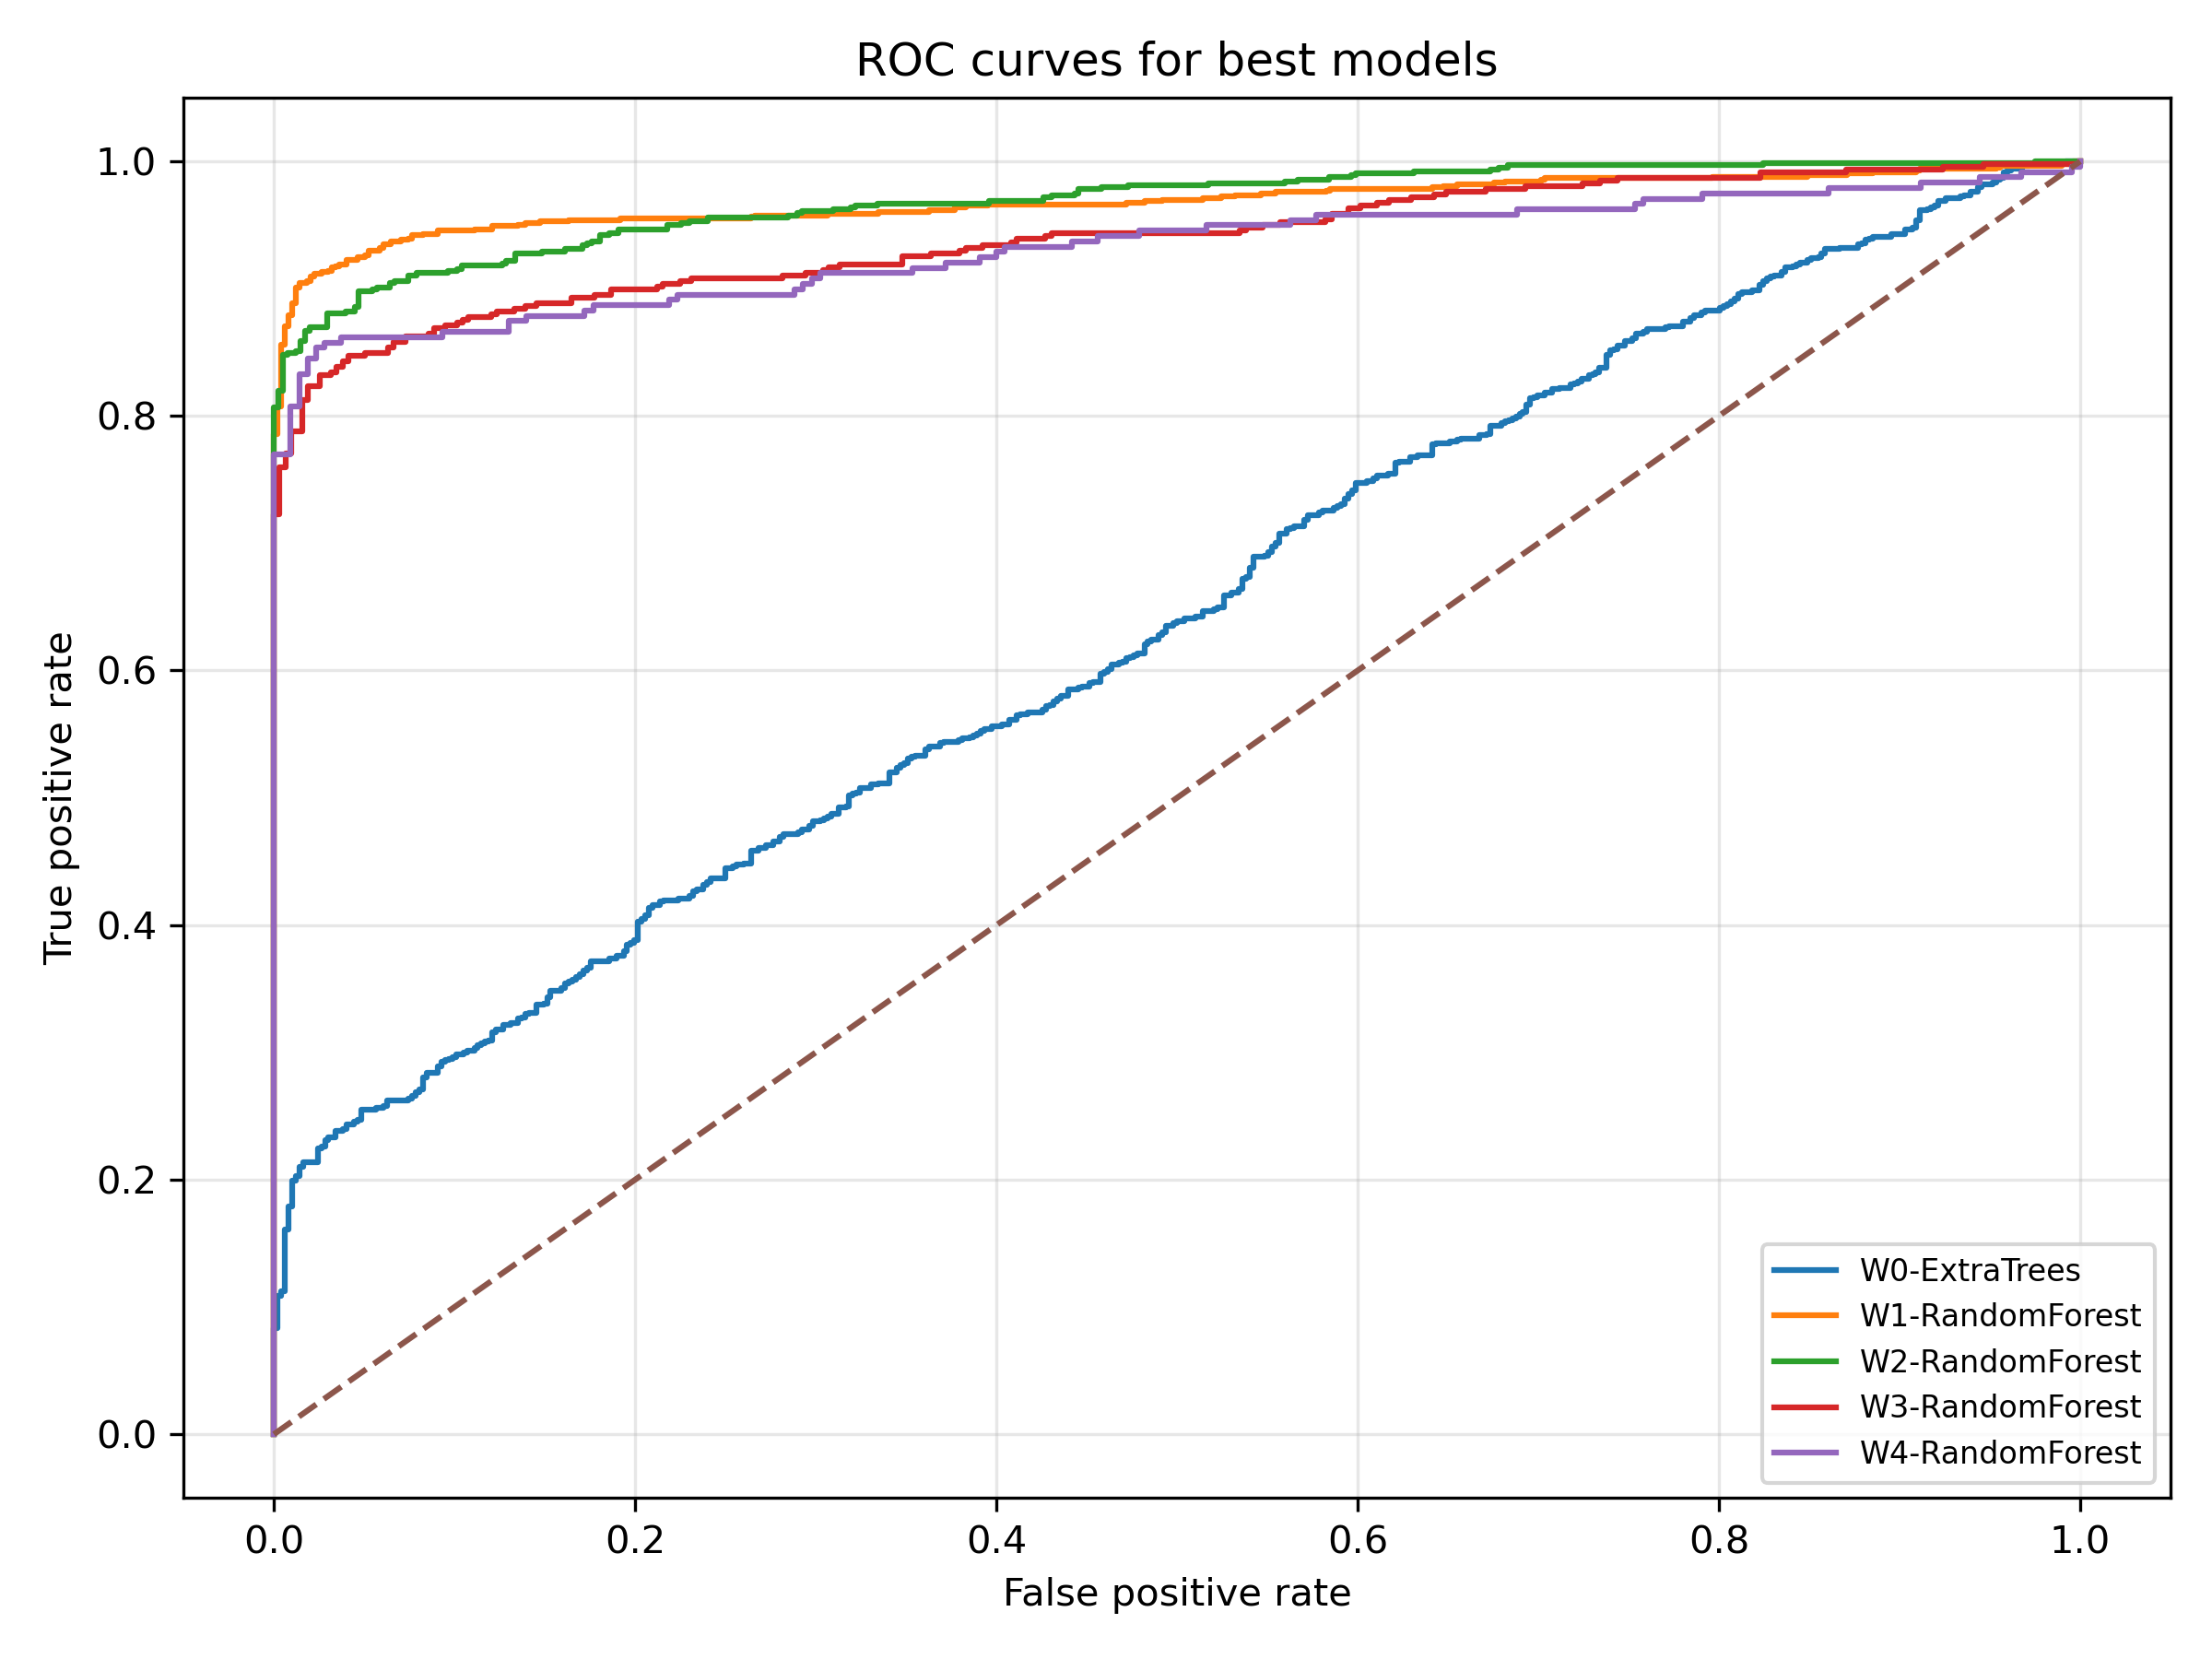

### 04_pr_best_models.png

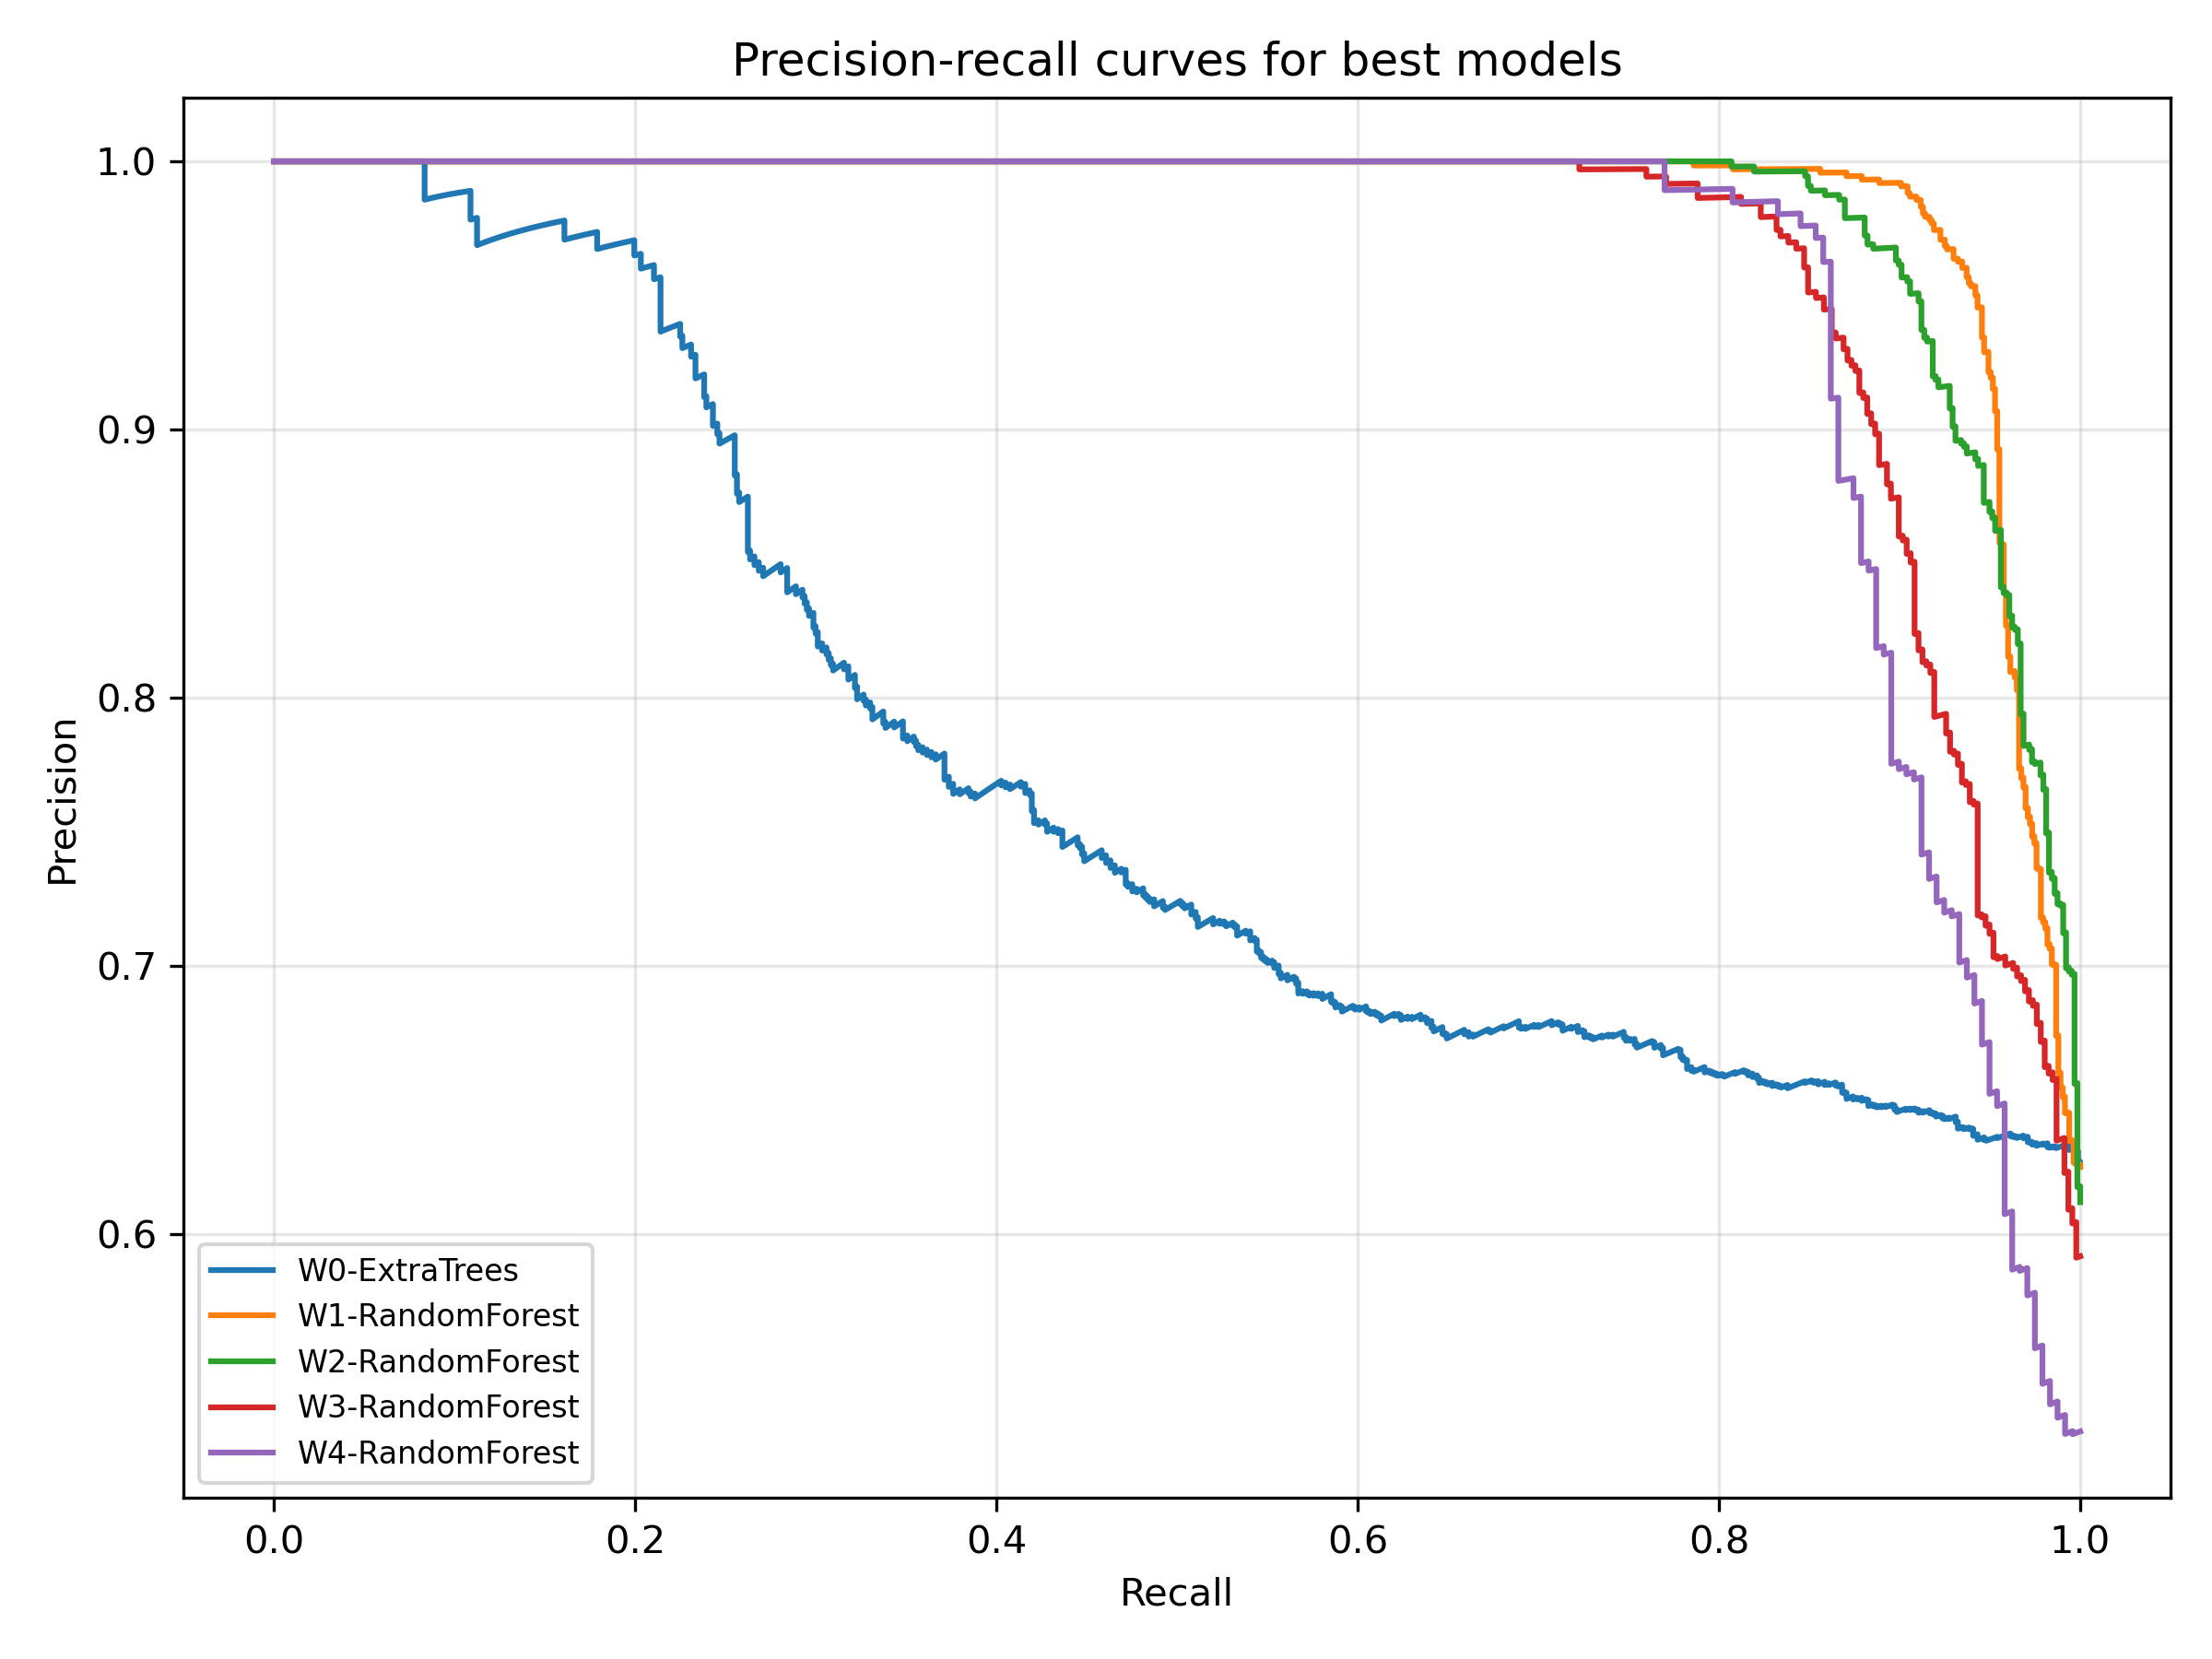

### 05_calibration_best_models.png

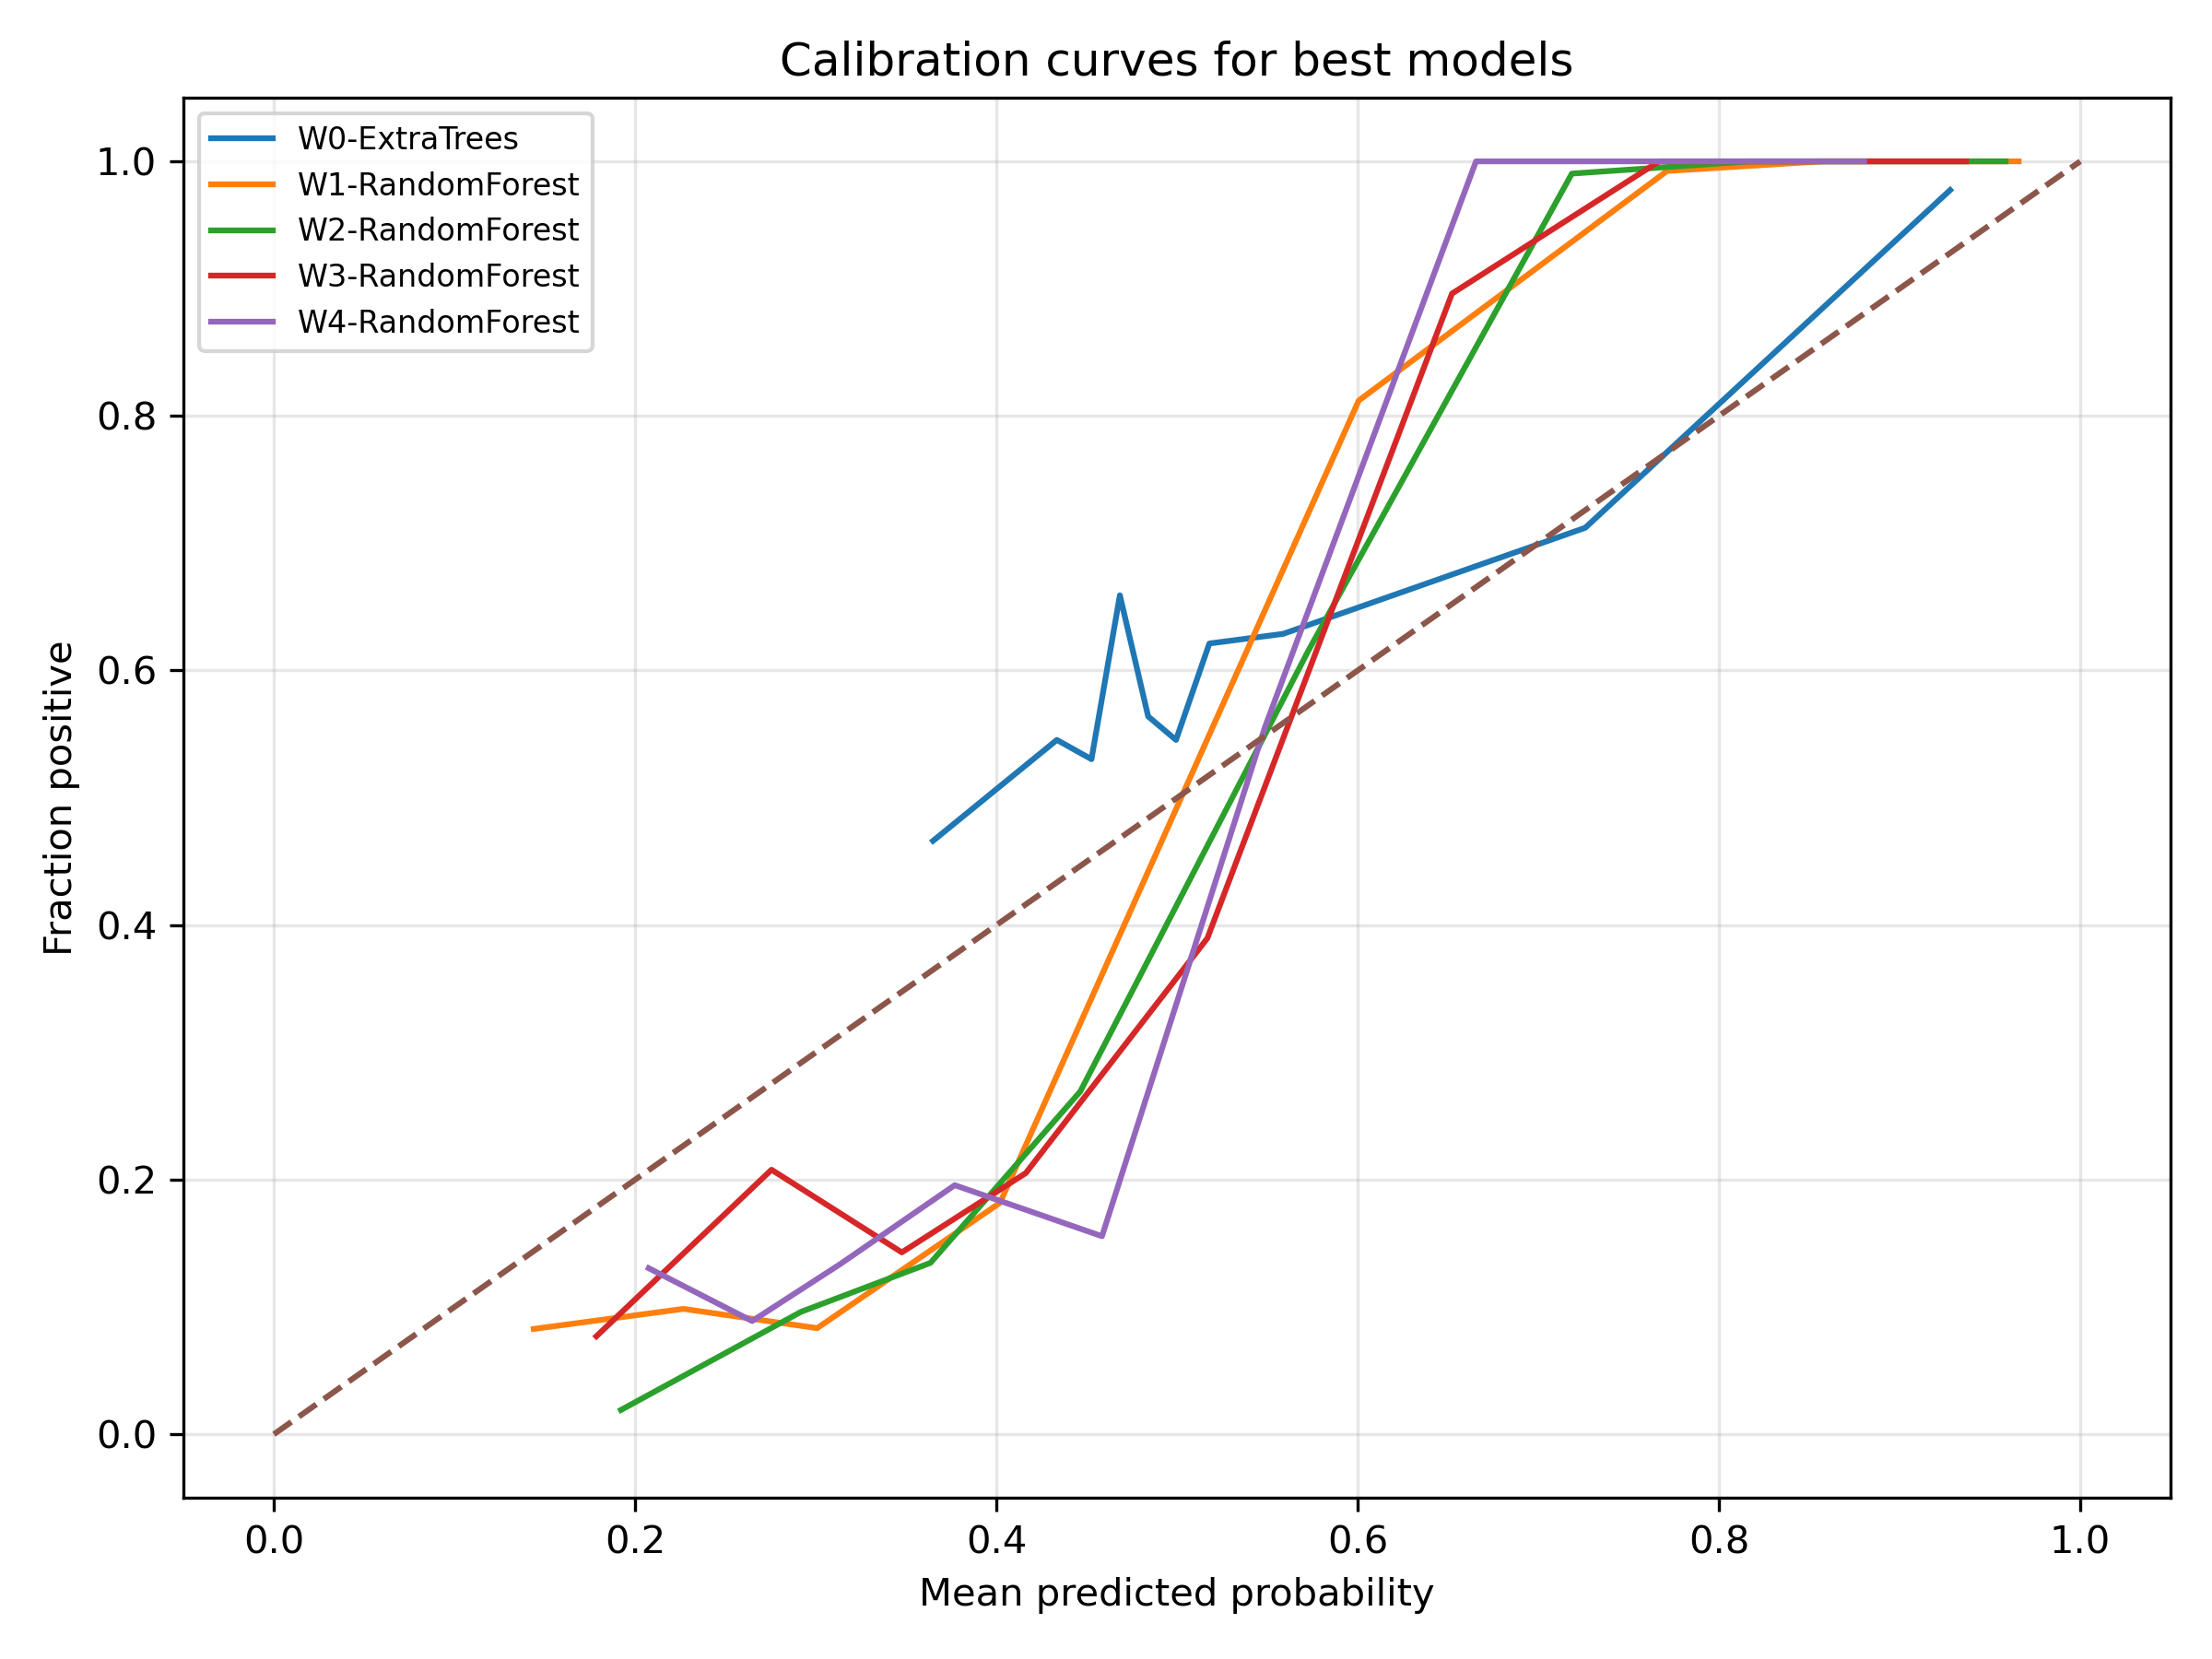

In [6]:
show_run_outputs(output_dir)

## Useful output files

After running, check these folders inside `output_dir`:

- `tables/`
  - `03_metrics_by_window_model.csv`
  - `04_thresholds.csv`
  - `05_roc_curve_points.csv`
  - `06_pr_curve_points.csv`
  - `07_calibration_curve_points.csv`
  - `10_best_model_per_window.csv`
- `predictions/`
  - `all_test_predictions.csv`
- `feature_importance/`
  - `all_top_feature_importances.csv`
- `plots/`
  - window cohort plot
  - metric trend plot
  - ROC, PR, calibration plots
  - confusion matrices
  - top-feature charts

